# Indian Agricultural Statistics — Crop Production Forecasting
## Experiments 1–10 | Detailed Data Analytics + Machine Learning Notebook

### Project statement
**Develop a machine learning model to analyze historical agricultural statistics and forecast crop production trends in India using variables such as crop area, yield per hectare, land-use patterns and, where available, price/weather variables.**

### Dataset strategy
This version uses a **local CSV file** — `crop-wise-area-production-yield.csv` — placed next to this notebook. The file provides district-level crop statistics for India with the following columns:

`id, year, state_name, state_code, district_name, district_code, crop_name, crop_code, crop_type, season, area, area_unit, production, production_unit, yield, yield_unit`

The analytical pipeline is identical to the Kaggle-API version: business objective → data survey → EDA → feature engineering / PCA → hypothesis testing / dashboard → model comparison → model development → validation → interpretation → real-world recommendations. The only change is the data source (local CSV instead of Kaggle API download).


## Source references

1. Local dataset: `crop-wise-area-production-yield.csv` (district-level Indian crop area / production / yield).
2. scikit-learn documentation: https://scikit-learn.org/stable/
3. pandas documentation: https://pandas.pydata.org/docs/

The experiment documents emphasize: business objective → data-source survey → EDA → feature engineering/PCA → hypothesis testing/dashboard → model comparison → model development → validation → interpretation → real-world recommendations. This notebook preserves that organization.


# Experiment 01 — Understanding Business Objectives, Analytical Goals and Future Outcomes

## Aim
To develop an end-to-end data analytics and machine-learning framework that uses historical Indian agricultural statistics to forecast next-year crop production and convert the forecast into actionable agricultural decisions.

## Learning objectives
- Define the agricultural business problem.
- Identify measurable analytical goals.
- Define a leakage-safe forecasting target.
- Identify stakeholders and decisions supported by the model.
- Define success metrics before model training.

## Interim objectives
1. Load the local district-level crop dataset.
2. Audit schema, years, crops, states and missing values.
3. Build a harmonized crop-year analytical table.
4. Analyze historical production, area and yield patterns.
5. Engineer temporal and domain-specific features.
6. Test statistically meaningful relationships.
7. Benchmark multiple regression algorithms.
8. Validate the selected model using time-aware splits.
9. Interpret feature importance and forecasting errors.
10. Produce an agricultural decision-support matrix.

## Final business objective
Build a reproducible forecasting system that can estimate future crop production and help agricultural planners plan procurement/storage, identify crops with declining production, monitor productivity changes, evaluate the relationship between cultivated area and output, and prioritize crops/regions for closer monitoring.

## Key analytical questions
- Which crops have the strongest long-term production growth?
- Is production growth driven mainly by cultivated area or yield?
- Which crop/state combinations are difficult to forecast?
- Which variables are most predictive?
- Where should decision-makers focus monitoring resources?

## Success criteria
The final model is judged primarily by **RMSE and MAE**, with R² and MAPE as supporting metrics. Model selection must use only training/validation periods; the final future period is held out until the end.


In [1]:
# ============================================================
# SETUP — install libraries
# ============================================================
# Run this cell if packages are missing.
%pip -q install pandas numpy matplotlib seaborn scipy scikit-learn openpyxl python-docx statsmodels


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ============================================================
# SETUP — imports and reproducibility
# ============================================================
import os, re, json, time, glob, warnings, sys, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, mutual_info_regression
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error
)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    GradientBoostingRegressor, HistGradientBoostingRegressor
)
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

BASE = Path.cwd()
REPORT_DIR = BASE / "report_outputs"
REPORT_DIR.mkdir(exist_ok=True)

# Local dataset path
CSV_PATH = BASE / "crop-wise-area-production-yield.csv"

print("Working directory:", BASE)
print("Report directory:", REPORT_DIR)
print("Dataset path:", CSV_PATH, "- exists:", CSV_PATH.exists())


Working directory: C:\Users\SAMSUNG\Desktop\DA\project
Report directory: C:\Users\SAMSUNG\Desktop\DA\project\report_outputs
Dataset path: C:\Users\SAMSUNG\Desktop\DA\project\crop-wise-area-production-yield.csv - exists: True


# Experiment 02 — Survey of the Data Source

## Aim
To document the structure of the local crop dataset and confirm it covers production, area, yield, crop, season, state and district at a usable temporal/geographic resolution.

## Selected source
**File:** `crop-wise-area-production-yield.csv`

Core fields:
- `year` — crop year (string such as `1997-1998`; converted to a start-year integer).
- `state_name`, `district_name`, `season` — geographic / seasonal keys.
- `crop_name`, `crop_type` — crop identity and category.
- `area`, `production`, `yield` — the central agricultural quantities (with explicit unit columns).

## Why a single harmonized source?
This dataset already contains production, area and yield at crop × year × district × season granularity, which is exactly the resolution required for the forecasting target. Optional price/weather enrichment is attempted only when a compatible file is present; otherwise those steps are skipped safely without fabricating matches.


In [3]:
# ============================================================
# Load the local dataset
# ============================================================
if not CSV_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {CSV_PATH}. Place crop-wise-area-production-yield.csv next to this notebook.")

df_raw = pd.read_csv(CSV_PATH, low_memory=False)
print("Raw shape:", df_raw.shape)
print("Columns:", list(df_raw.columns))
display(df_raw.head())


Raw shape: (455359, 16)
Columns: ['id', 'year', 'state_name', 'state_code', 'district_name', 'district_code', 'crop_name', 'crop_code', 'crop_type', 'season', 'area', 'area_unit', 'production', 'production_unit', 'yield', 'yield_unit']


,id,year,state_name,state_code,district_name,district_code,crop_name,crop_code,crop_type,season,area,area_unit,production,production_unit,yield,yield_unit
0,0,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Arhar/Tur,202.0,Pulses,Kharif,21400.0,Hectare,2600.0,Tonnes,0.121,Tonnes/Hectare
1,1,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Bajra,103.0,Cereals,Kharif,1400.0,Hectare,500.0,Tonnes,0.357,Tonnes/Hectare
2,2,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Castor Seed,1002.0,Oilseeds,Kharif,1000.0,Hectare,100.0,Tonnes,0.100,Tonnes/Hectare
3,3,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Cotton(Lint),1101.0,Fiber Crops,Kharif,7300.0,Hectare,9400.0,Tonnes,1.288,Tonnes/Hectare
4,4,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Dry Chillies,502.0,Spices,Kharif,3700.0,Hectare,7100.0,Tonnes,1.919,Tonnes/Hectare


In [4]:
# ============================================================
# Dataset inventory (schema audit of the local source)
# ============================================================
inventory = [{
    "file": CSV_PATH.name,
    "extension": CSV_PATH.suffix,
    "size_MB": round(CSV_PATH.stat().st_size / 1024**2, 2),
    "rows": len(df_raw),
    "columns": len(df_raw.columns),
    "column_names": ", ".join(map(str, df_raw.columns[:20]))
}]
inventory_df = pd.DataFrame(inventory)
display(inventory_df)

# No separate enrichment files are available with this single-CSV source.
tabular_files = [CSV_PATH]
enrichment_inventory = []


,file,extension,size_MB,rows,columns,column_names
0,crop-wise-area-production-yield.csv,.csv,53.62,455359,16,"id, year, state_name, state_code, district_nam..."


# Experiment 03 — Data Exploration and Descriptive Analysis

## Aim
To understand the structure, quality, distribution and relationships in the agricultural data before modeling.

## Analysis plan
1. Standardize column names.
2. Convert the crop-year string to an integer start year.
3. Inspect data types and missing values.
4. Remove impossible negative area/production values.
5. Validate/compute yield.
6. Analyze crop/state/season distributions.
7. Plot national and crop-level trends.
8. Examine area–yield–production relationships.
9. Detect outliers using IQR.


In [5]:
# ============================================================
# Standardize agricultural production schema
# ============================================================
df = df_raw.copy()
df.columns = [
    re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")
    for c in df.columns
]

# Common aliases (maps this CSV's names to the standard schema)
aliases = {
    "crop_year": ["crop_year", "year", "cropyear"],
    "crop": ["crop", "crop_name", "commodity"],
    "area": ["area", "cultivated_area", "area_hectares", "acreage"],
    "production": ["production", "crop_production", "output"],
    "yield": ["yield", "yield_per_hectare", "productivity"],
    "state": ["state_name", "state", "state_ut", "state_ut_name"],
    "district": ["district_name", "district"],
    "season": ["season", "crop_season"],
    "crop_type": ["crop_type", "croptype"]
}

def first_match(columns, options):
    for o in options:
        if o in columns:
            return o
    return None

rename = {}
for target, options in aliases.items():
    m = first_match(df.columns, options)
    if m:
        rename[m] = target
df = df.rename(columns=rename)

# ---- Handle crop_year stored as a string like "1997-1998" ----
# Extract the first 4-digit year as the integer crop year.
if df["crop_year"].dtype == object:
    df["crop_year"] = (
        df["crop_year"].astype(str)
          .str.extract(r"(\d{4})", expand=False)
    )
df["crop_year"] = pd.to_numeric(df["crop_year"], errors="coerce")

required = ["crop_year", "crop", "area", "production"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}. Available: {df.columns.tolist()}")

for c in ["area", "production", "yield"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

df["crop"] = df["crop"].astype(str).str.strip()
if "season" in df.columns:
    df["season"] = df["season"].astype(str).str.strip()

if "yield" not in df.columns:
    df["yield"] = df["production"] / df["area"]

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["crop_year", "crop", "area", "production"])
df = df[(df["area"] > 0) & (df["production"] >= 0)].copy()
df["yield"] = df["production"] / df["area"]
df["crop_year"] = df["crop_year"].astype(int)

print("Cleaned shape:", df.shape)
display(df.head())


Cleaned shape: (450350, 16)


,id,crop_year,state,state_code,district,district_code,crop,crop_code,crop_type,season,area,area_unit,production,production_unit,yield,yield_unit
0,0,1997,Andhra Pradesh,28,Ananthapuramu,502,Arhar/Tur,202.0,Pulses,Kharif,21400.0,Hectare,2600.0,Tonnes,0.121495,Tonnes/Hectare
1,1,1997,Andhra Pradesh,28,Ananthapuramu,502,Bajra,103.0,Cereals,Kharif,1400.0,Hectare,500.0,Tonnes,0.357143,Tonnes/Hectare
2,2,1997,Andhra Pradesh,28,Ananthapuramu,502,Castor Seed,1002.0,Oilseeds,Kharif,1000.0,Hectare,100.0,Tonnes,0.100000,Tonnes/Hectare
3,3,1997,Andhra Pradesh,28,Ananthapuramu,502,Cotton(Lint),1101.0,Fiber Crops,Kharif,7300.0,Hectare,9400.0,Tonnes,1.287671,Tonnes/Hectare
4,4,1997,Andhra Pradesh,28,Ananthapuramu,502,Dry Chillies,502.0,Spices,Kharif,3700.0,Hectare,7100.0,Tonnes,1.918919,Tonnes/Hectare


In [6]:
# Dataset structure and quality
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean()*100).round(2),
    "unique": df.nunique()
}).sort_values("missing_pct", ascending=False)
display(quality)

print("Duplicate rows:", df.duplicated().sum())
print("Years:", df["crop_year"].min(), "to", df["crop_year"].max())
print("Unique crops:", df["crop"].nunique())
for c in ["state", "district", "season"]:
    if c in df.columns:
        print(c, "unique:", df[c].nunique())


,dtype,missing,missing_pct,unique
id,int64,0,0.0,450350
crop_year,int32,0,0.0,26
state,object,0,0.0,34
state_code,int64,0,0.0,34
district,object,0,0.0,737
district_code,int64,0,0.0,740
crop,object,0,0.0,115
crop_code,float64,21,0.0,94
crop_type,object,0,0.0,10
season,object,0,0.0,7


Duplicate rows: 0
Years: 1997 to 2022
Unique crops: 115
state unique: 34
district unique: 737
season unique: 7


In [7]:
# 5-point / descriptive summary
summary = df[["crop_year", "area", "production", "yield"]].describe(
    percentiles=[0.25, 0.50, 0.75]
).T
summary["IQR"] = summary["75%"] - summary["25%"]
display(summary)


,count,mean,std,min,25%,50%,75%,max,IQR
crop_year,450350.0,2010.623906,7.446122e+00,1997.000,2004.000000,2011.000000,2017.000000,2.022000e+03,13.000000
area,450350.0,13264.579665,4.869827e+04,0.008,83.000000,617.000000,4900.000000,8.580100e+06,4817.000000
production,450350.0,838031.983951,2.028612e+07,0.000,91.000000,808.000000,8350.000000,1.597800e+09,8259.000000
yield,450350.0,69.610939,8.664629e+02,0.000,0.578598,1.070028,2.586207,4.395833e+04,2.007609


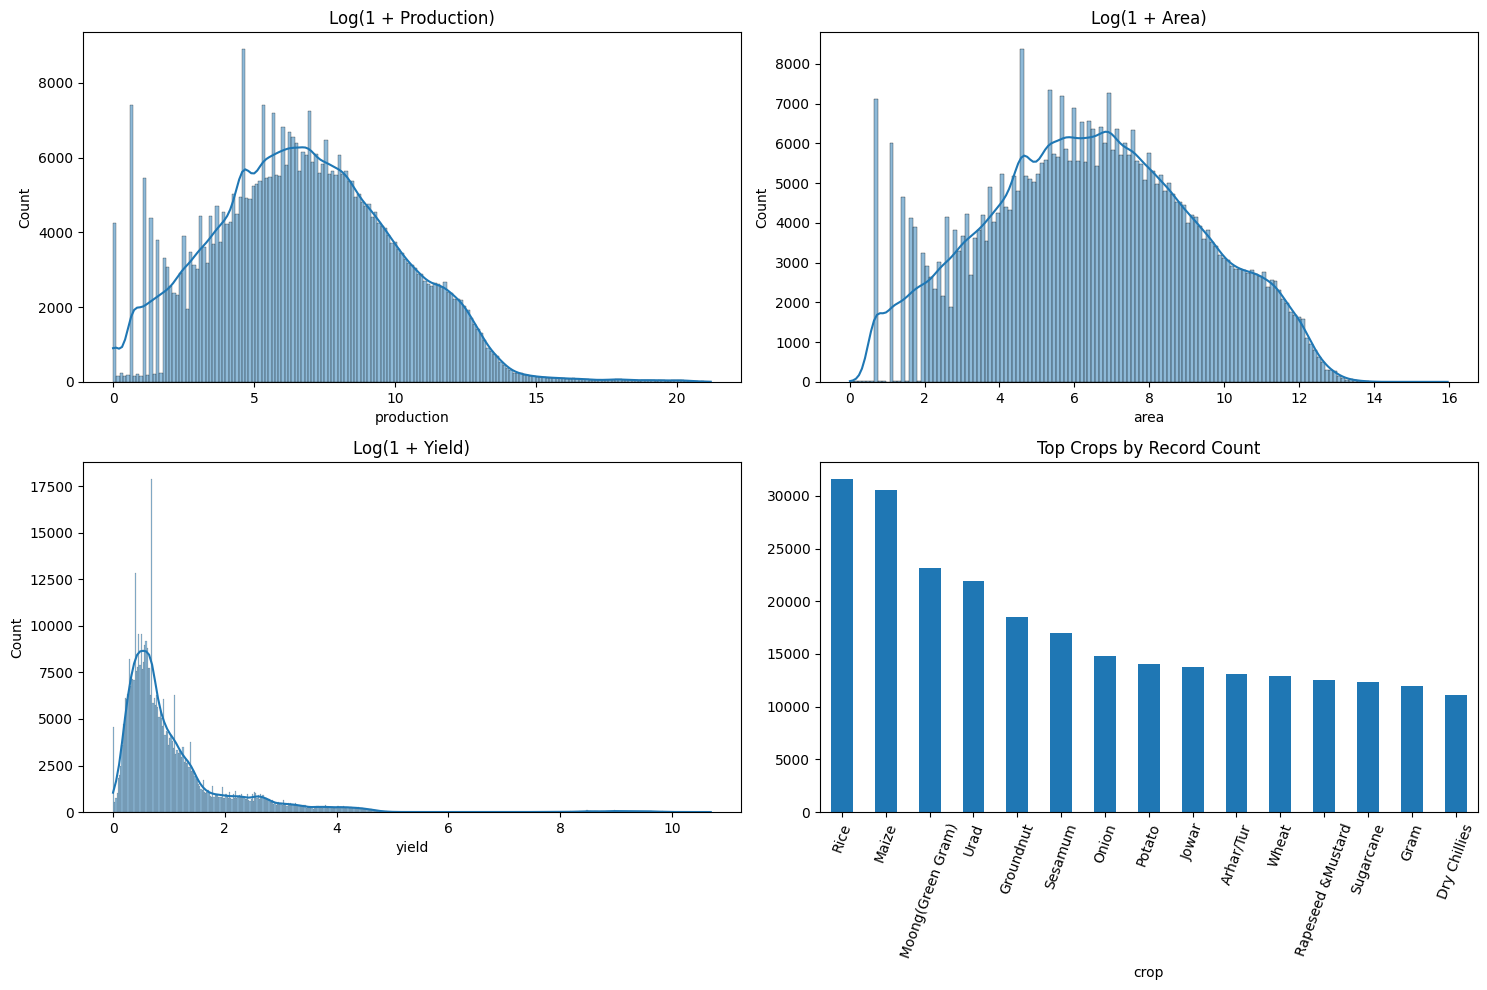

In [8]:
# Univariate distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(np.log1p(df["production"]), kde=True, ax=axes[0,0])
axes[0,0].set_title("Log(1 + Production)")

sns.histplot(np.log1p(df["area"]), kde=True, ax=axes[0,1])
axes[0,1].set_title("Log(1 + Area)")

sns.histplot(np.log1p(df["yield"]), kde=True, ax=axes[1,0])
axes[1,0].set_title("Log(1 + Yield)")

df["crop"].value_counts().head(15).plot(kind="bar", ax=axes[1,1])
axes[1,1].set_title("Top Crops by Record Count")
axes[1,1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.savefig(REPORT_DIR / "exp3_univariate.png", dpi=180)
plt.show()


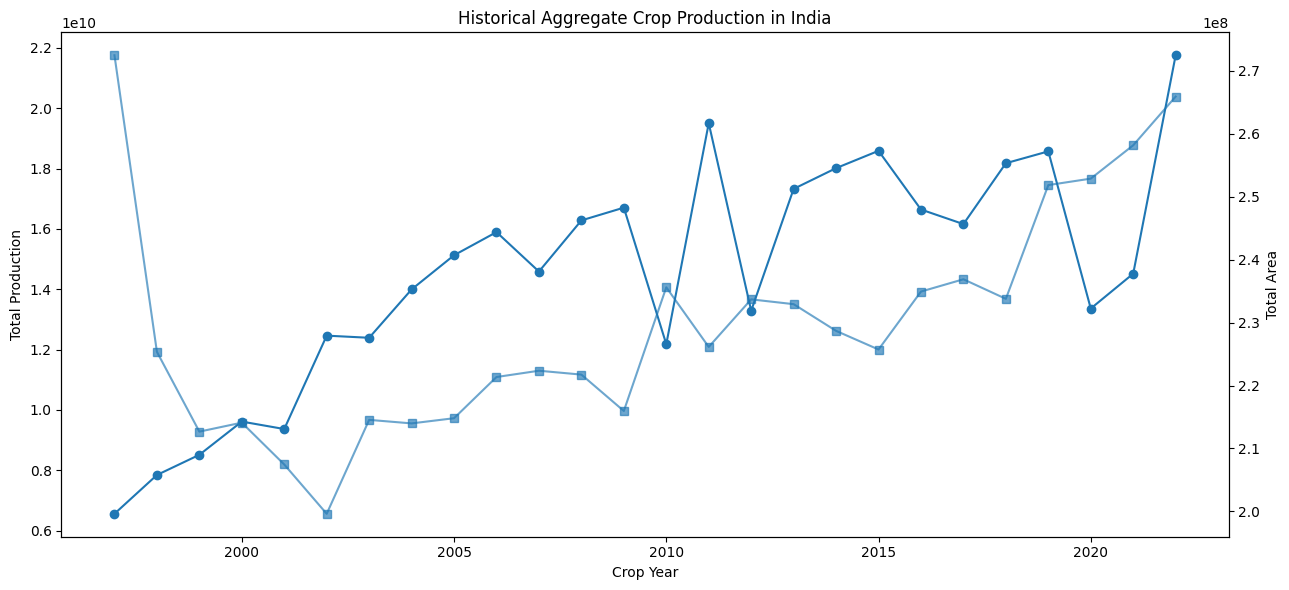

In [9]:
# Historical national production trend
annual = (
    df.groupby("crop_year", as_index=False)
      .agg(
          total_production=("production", "sum"),
          total_area=("area", "sum"),
          mean_yield=("yield", "mean")
      )
      .sort_values("crop_year")
)

fig, ax1 = plt.subplots(figsize=(13, 6))
ax1.plot(annual["crop_year"], annual["total_production"], marker="o")
ax1.set_xlabel("Crop Year")
ax1.set_ylabel("Total Production")
ax1.set_title("Historical Aggregate Crop Production in India")

ax2 = ax1.twinx()
ax2.plot(annual["crop_year"], annual["total_area"], marker="s", alpha=0.65)
ax2.set_ylabel("Total Area")

plt.tight_layout()
plt.savefig(REPORT_DIR / "exp3_national_trend.png", dpi=180)
plt.show()


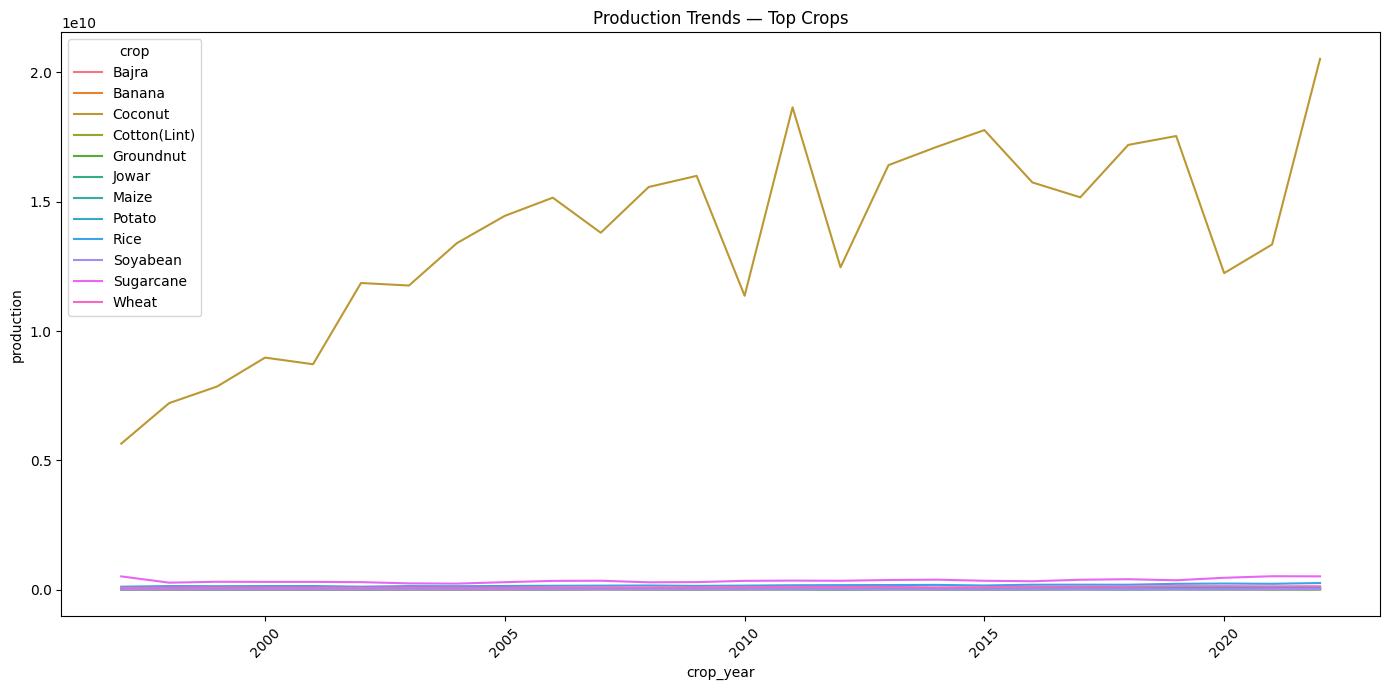

In [10]:
# Top crop trends
top_crops = df.groupby("crop")["production"].sum().nlargest(12).index
crop_year = (
    df[df["crop"].isin(top_crops)]
      .groupby(["crop_year", "crop"], as_index=False)["production"].sum()
)

plt.figure(figsize=(14, 7))
sns.lineplot(data=crop_year, x="crop_year", y="production", hue="crop")
plt.title("Production Trends — Top Crops")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp3_top_crop_trends.png", dpi=180)
plt.show()


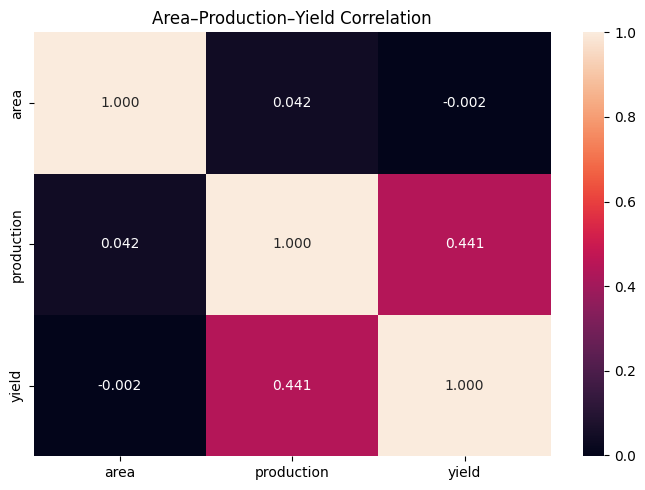

In [11]:
# Multivariate analysis
corr = df[["area", "production", "yield"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".3f")
plt.title("Area–Production–Yield Correlation")
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp3_correlation.png", dpi=180)
plt.show()


In [12]:
# IQR-based outlier counts
outlier_rows = []
for c in ["area", "production", "yield"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    count = ((df[c] < lo) | (df[c] > hi)).sum()
    outlier_rows.append([c, lo, hi, count, count/len(df)*100])

outliers = pd.DataFrame(
    outlier_rows,
    columns=["feature", "lower_bound", "upper_bound", "outlier_count", "outlier_pct"]
)
display(outliers)


,feature,lower_bound,upper_bound,outlier_count,outlier_pct
0,area,-7142.500000,12125.500000,74970,16.647052
1,production,-12297.500000,20738.500000,79643,17.684690
2,yield,-2.432816,5.597621,65855,14.623071


## Experiment 03 — Observation checklist

After running the cells, record: dataset size after cleaning, temporal coverage, number of crops/states/districts, dominant crops, production/area/yield trend direction, strongest pairwise correlations and major outlier variables. Do not convert correlation into a causal statement.


# Experiment 04 — Feature Engineering, Variable Selection and Dimensionality Reduction

## Feature groups
**Historical production:** lag-1, lag-2, rolling mean, rolling std.
**Land-use / area:** current area, lagged area, area growth.
**Productivity:** current yield, lagged yield, yield growth.
**Market / Weather:** added only when a compatible enrichment file exists.
**Time:** crop year.

## Leakage rule
All lag and rolling features are shifted so that the prediction for year `t+1` never uses production from year `t+1` or later.


In [13]:
# ============================================================
# Build a crop-year master table
# ============================================================
group_cols = [c for c in ["state", "district", "season", "crop"] if c in df.columns]

if group_cols:
    base = (
        df.groupby(["crop_year"] + group_cols, as_index=False)
          .agg(area=("area","sum"),
               production=("production","sum"),
               yield_per_ha=("yield","mean"))
    )
else:
    base = (
        df.groupby(["crop_year","crop"], as_index=False)
          .agg(area=("area","sum"),
               production=("production","sum"),
               yield_per_ha=("yield","mean"))
    )

sort_cols = [c for c in ["state","district","season","crop"] if c in base.columns] + ["crop_year"]
base = base.sort_values(sort_cols).copy()

temporal_group = [c for c in ["state","district","season","crop"] if c in base.columns]
if not temporal_group:
    temporal_group = ["crop"]

for lag in [1,2]:
    for col in ["production","area","yield_per_ha"]:
        base[f"{col}_lag_{lag}"] = base.groupby(temporal_group)[col].shift(lag)

base["area_growth"] = base.groupby(temporal_group)["area"].pct_change()
base["yield_growth"] = base.groupby(temporal_group)["yield_per_ha"].pct_change()
base["production_growth"] = base.groupby(temporal_group)["production"].pct_change()

shifted_prod = base.groupby(temporal_group)["production"].shift(1)
base["production_roll_mean_3"] = (
    shifted_prod.groupby([base[c] for c in temporal_group])
                .transform(lambda s: s.rolling(3, min_periods=1).mean())
)
base["production_roll_std_3"] = (
    shifted_prod.groupby([base[c] for c in temporal_group])
                .transform(lambda s: s.rolling(3, min_periods=2).std())
)

# Next-year target
base["target_next_year_production"] = (
    base.groupby(temporal_group)["production"].shift(-1)
)

print("Engineered table:", base.shape)
display(base.head())


Engineered table: (450350, 20)


,crop_year,state,district,season,crop,area,production,yield_per_ha,production_lag_1,area_lag_1,yield_per_ha_lag_1,production_lag_2,area_lag_2,yield_per_ha_lag_2,area_growth,yield_growth,production_growth,production_roll_mean_3,production_roll_std_3,target_next_year_production
197534,2010,Andaman And Nicobar Islands,Nicobars,Autumn,Rice,3.50,10.0,2.857143,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.5
213797,2011,Andaman And Nicobar Islands,Nicobars,Autumn,Rice,1.50,2.5,1.666667,10.0,3.50,2.857143,NaN,NaN,NaN,-0.571429,-0.416667,-0.750000,10.000000,NaN,0.4
231621,2012,Andaman And Nicobar Islands,Nicobars,Autumn,Rice,0.35,0.4,1.142857,2.5,1.50,1.666667,10.0,3.50,2.857143,-0.766667,-0.314286,-0.840000,6.250000,5.303301,6.3
248597,2013,Andaman And Nicobar Islands,Nicobars,Autumn,Rice,2.65,6.3,2.377358,0.4,0.35,1.142857,2.5,1.50,1.666667,6.571429,1.080189,14.750000,4.300000,5.046781,10.8
266997,2014,Andaman And Nicobar Islands,Nicobars,Autumn,Rice,4.60,10.8,2.347826,6.3,2.65,2.377358,0.4,0.35,1.142857,0.735849,-0.012422,0.714286,3.066667,2.990541,11.2


In [14]:
# ============================================================
# Optional price / weather enrichment (safe no-op for single CSV)
# ============================================================
# With this single local dataset there are no separate price or weather
# files, so no row-level joins are performed. The pipeline continues using
# production / area / yield history, exactly as designed to degrade safely.

def normalize_cols(x):
    x = x.copy()
    x.columns = [re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_") for c in x.columns]
    return x

price_df = None
price_path = None
weather_path = None

print("Files available for optional enrichment:")
for p in tabular_files:
    print(" -", p.name)
print("\nNo separate price/weather source detected. Price & weather features remain unavailable.")


Files available for optional enrichment:
 - crop-wise-area-production-yield.csv

No separate price/weather source detected. Price & weather features remain unavailable.


Features before variance filter: 11
Features after variance filter: 11


,feature,mutual_information
2,production_lag_1,1.190662
8,production_roll_mean_3,1.162227
3,production_lag_2,1.003087
0,area,0.756549
9,production_roll_std_3,0.656289
4,area_lag_1,0.638601
1,yield_per_ha,0.371206
5,yield_per_ha_lag_1,0.304945
6,area_growth,0.175668
10,crop_year,0.164889


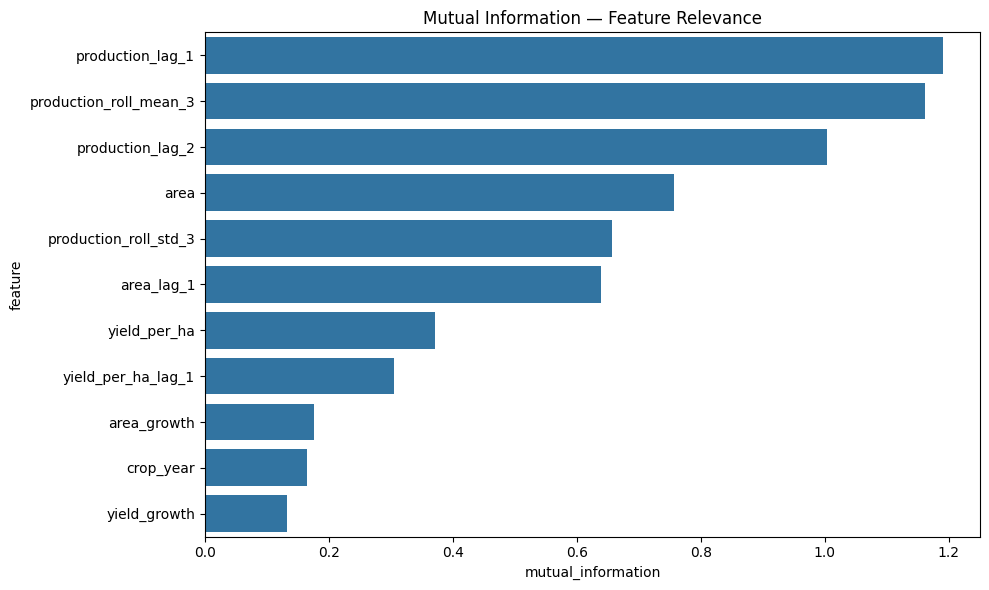

In [15]:
# ============================================================
# Feature selection + PCA
# ============================================================
numeric_features = [
    "area", "yield_per_ha",
    "production_lag_1", "production_lag_2",
    "area_lag_1", "yield_per_ha_lag_1",
    "area_growth", "yield_growth",
    "production_roll_mean_3", "production_roll_std_3",
    "crop_year", "price_indicator", "price_growth"
]
numeric_features = [c for c in numeric_features if c in base.columns]

selection_df = base[numeric_features + ["target_next_year_production"]].replace(
    [np.inf, -np.inf], np.nan
).copy()

X_sel = selection_df[numeric_features].fillna(
    selection_df[numeric_features].median(numeric_only=True)
)
y_sel = selection_df["target_next_year_production"]

vt = VarianceThreshold(threshold=1e-8)
X_vt = vt.fit_transform(X_sel)
kept = [c for c, k in zip(numeric_features, vt.get_support()) if k]

print("Features before variance filter:", len(numeric_features))
print("Features after variance filter:", len(kept))

mi = mutual_info_regression(
    X_sel[kept], y_sel.fillna(y_sel.median()),
    random_state=RANDOM_STATE
)
mi_df = pd.DataFrame({"feature": kept, "mutual_information": mi}).sort_values("mutual_information", ascending=False)
display(mi_df)

plt.figure(figsize=(10,6))
sns.barplot(data=mi_df, x="mutual_information", y="feature")
plt.title("Mutual Information — Feature Relevance")
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp4_mutual_information.png", dpi=180)
plt.show()


Components needed for >=85% variance: 6


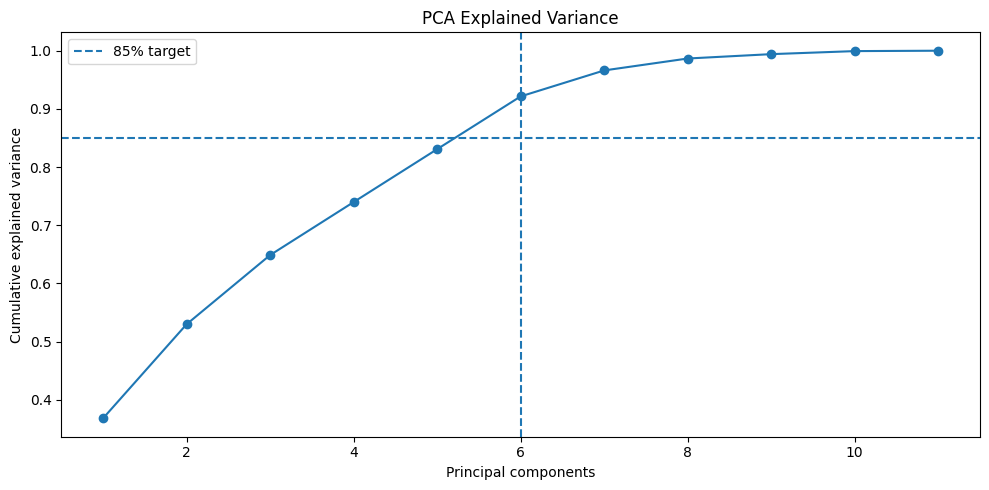

In [16]:
# PCA on numeric feature space
X_scaled = StandardScaler().fit_transform(X_sel[kept])
pca = PCA().fit(X_scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)
n85 = int(np.argmax(cum_var >= 0.85) + 1)
print("Components needed for >=85% variance:", n85)

plt.figure(figsize=(10,5))
plt.plot(range(1, len(cum_var)+1), cum_var, marker="o")
plt.axhline(0.85, linestyle="--", label="85% target")
plt.axvline(n85, linestyle="--")
plt.xlabel("Principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp4_pca.png", dpi=180)
plt.show()


# Experiment 05 — Hypothesis Testing, Dashboards, Visualization and Recommendations

## Agricultural hypotheses
**H1 — High-area vs low-area productivity:** H₀ mean yield equal; H₁ differs.
**H2 — Production growth vs yield:** H₀ mean yield equal for positive/negative growth; H₁ differs.
**H3 — Crop-level yield differences:** H₀ all major crops equal mean yield; H₁ at least one differs.

A p-value below 0.05 is evidence against H₀; it does not prove causation.


In [17]:
# ============================================================
# Hypothesis testing
# ============================================================
test = base.replace([np.inf,-np.inf],np.nan).copy()

test["area_group"] = np.where(test["area"] >= test["area"].median(), "High Area", "Low Area")
test["growth_group"] = np.where(test["production_growth"] >= 0, "Positive Growth", "Negative Growth")
test = test.dropna(subset=["yield_per_ha"])

high = test.loc[test["area_group"]=="High Area","yield_per_ha"]
low  = test.loc[test["area_group"]=="Low Area","yield_per_ha"]

welch_t, welch_p = stats.ttest_ind(high, low, equal_var=False)
mw_u, mw_p = stats.mannwhitneyu(high, low, alternative="two-sided")
print("H1 — Welch t-test:", welch_t, welch_p)
print("H1 — Mann-Whitney U:", mw_u, mw_p)

pos = test.loc[test["growth_group"]=="Positive Growth","yield_per_ha"].dropna()
neg = test.loc[test["growth_group"]=="Negative Growth","yield_per_ha"].dropna()
if len(pos)>1 and len(neg)>1:
    t2,p2 = stats.ttest_ind(pos,neg,equal_var=False)
    u2,up2 = stats.mannwhitneyu(pos,neg,alternative="two-sided")
    print("H2 — Welch:", t2,p2)
    print("H2 — Mann-Whitney:", u2,up2)


H1 — Welch t-test: 19.59860773431819 1.7445485713989568e-85
H1 — Mann-Whitney U: 26625739136.0 1.8064767859127719e-187
H2 — Welch: 13.287101973049593 2.807969166018025e-40
H2 — Mann-Whitney: 28496262904.0 0.0


In [18]:
# H3 — ANOVA across top crops
top10 = test["crop"].value_counts().head(10).index
groups = [test.loc[test["crop"]==c,"yield_per_ha"].dropna() for c in top10]
groups = [g for g in groups if len(g)>1]
if len(groups) >= 2:
    F, p_anova = stats.f_oneway(*groups)
    print("H3 — ANOVA F:", F)
    print("H3 — p-value:", p_anova)


H3 — ANOVA F: 2010.8362649899507
H3 — p-value: 0.0


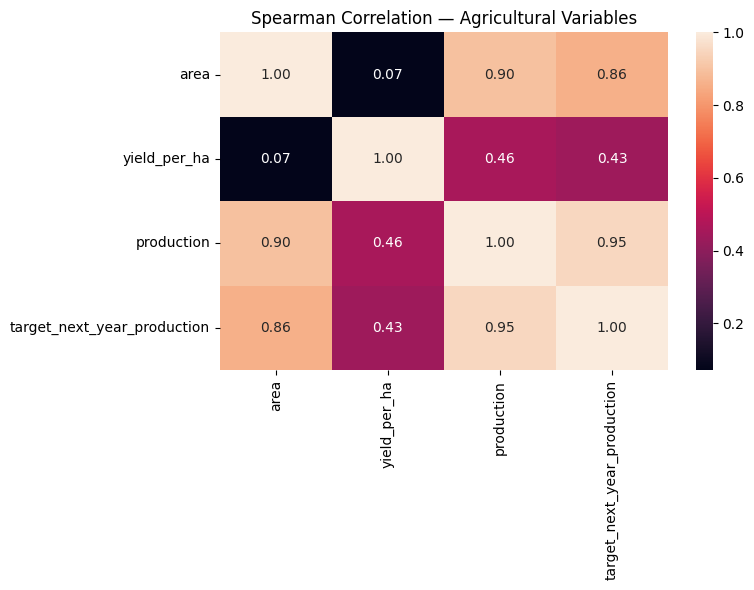

In [19]:
# Correlation analysis (Spearman)
corr_spearman = test[["area","yield_per_ha","production","target_next_year_production"]].corr(method="spearman")
plt.figure(figsize=(8,6))
sns.heatmap(corr_spearman, annot=True, fmt=".2f")
plt.title("Spearman Correlation — Agricultural Variables")
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp5_correlation.png", dpi=180)
plt.show()


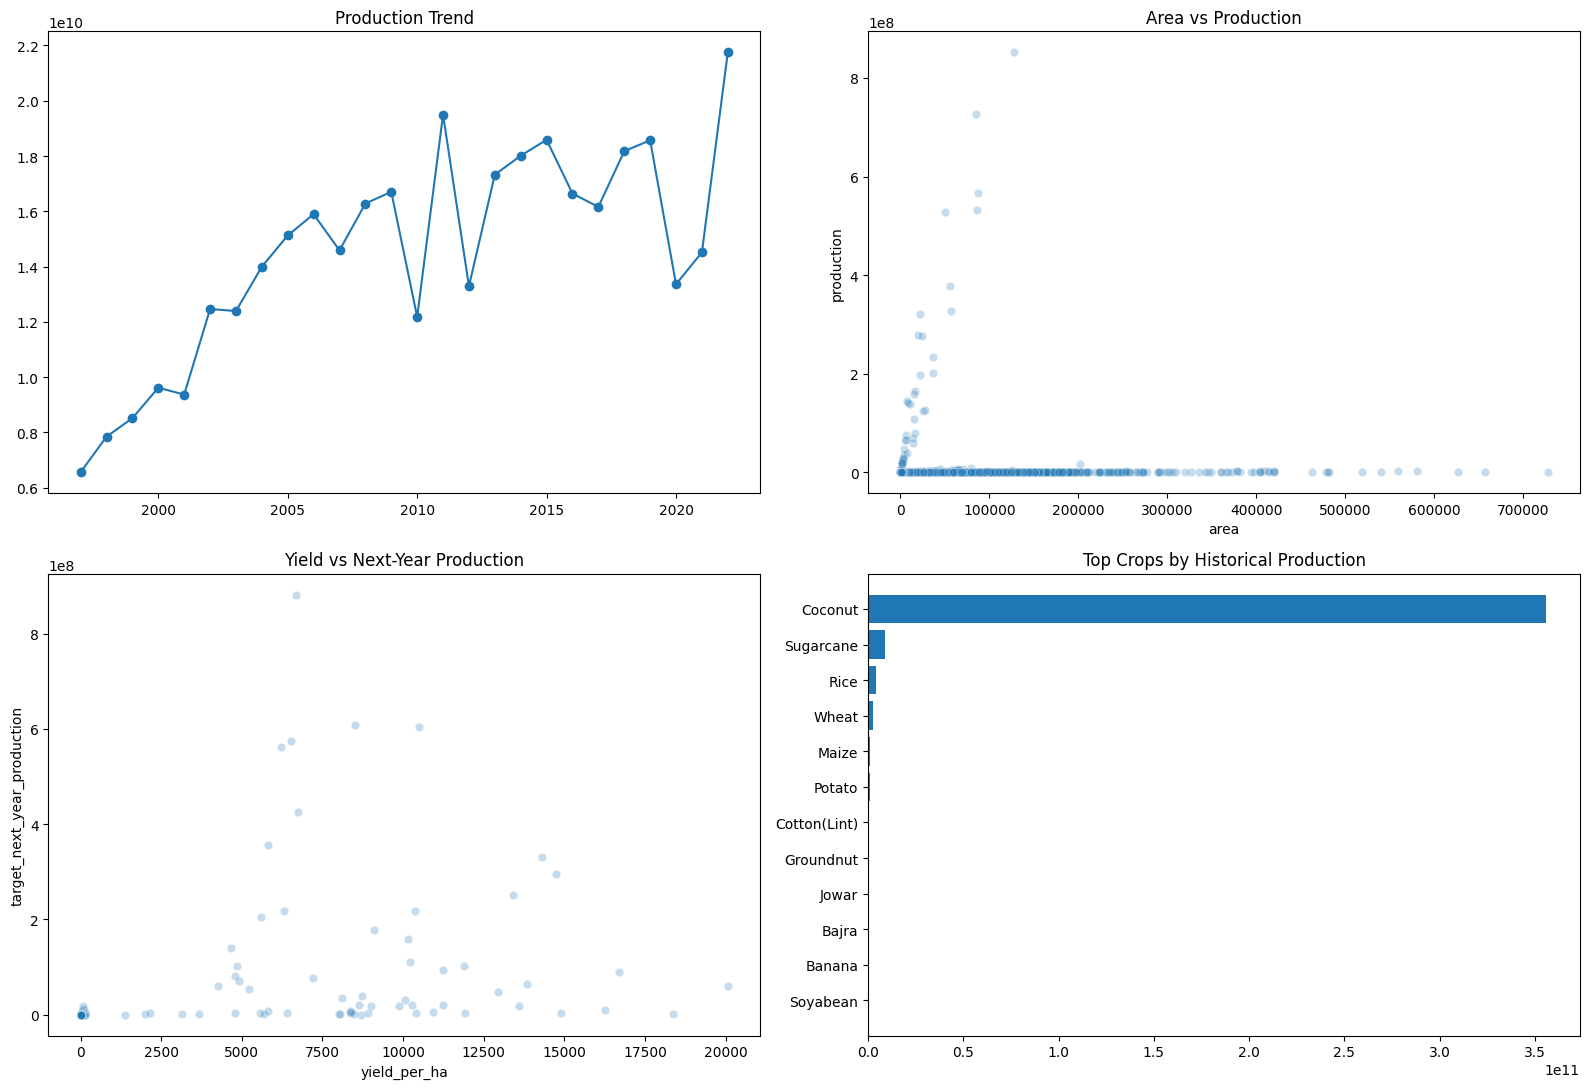

In [20]:
# Dashboard-style overview
fig, axes = plt.subplots(2,2,figsize=(16,11))

annual2 = base.groupby("crop_year",as_index=False)["production"].sum()
axes[0,0].plot(annual2["crop_year"], annual2["production"], marker="o")
axes[0,0].set_title("Production Trend")

sns.scatterplot(data=test.sample(min(10000,len(test)),random_state=42), x="area", y="production", alpha=.25, ax=axes[0,1])
axes[0,1].set_title("Area vs Production")

sns.scatterplot(data=test.sample(min(10000,len(test)),random_state=42), x="yield_per_ha", y="target_next_year_production", alpha=.25, ax=axes[1,0])
axes[1,0].set_title("Yield vs Next-Year Production")

top_crop_prod = base.groupby("crop")["production"].sum().nlargest(12).sort_values()
axes[1,1].barh(top_crop_prod.index, top_crop_prod.values)
axes[1,1].set_title("Top Crops by Historical Production")

plt.tight_layout()
plt.savefig(REPORT_DIR / "exp5_dashboard.png", dpi=180)
plt.show()


# Experiment 06 — Identification of Traditional and Contemporary Statistical Methods

### Traditional / simpler models
1. Linear Regression  2. Ridge  3. Lasso  4. Linear SVR

### Contemporary / non-linear models
5. Random Forest  6. Extra Trees  7. Gradient Boosting  8. HistGradientBoosting

### Metrics
MAE, RMSE, R², MAPE, training time, inference latency.


In [21]:
# ============================================================
# Rebuild the crop-year forecasting table after all enrichments
# ============================================================
agg_keys = ["crop_year","crop"]
if "season" in base.columns:
    agg_keys.append("season")

agg_spec = {
    "area": ("area","sum"),
    "production": ("production","sum"),
    "yield_per_ha": ("yield_per_ha","mean"),
    "production_lag_1": ("production_lag_1","sum"),
    "production_lag_2": ("production_lag_2","sum"),
    "area_lag_1": ("area_lag_1","sum"),
    "yield_lag_1": ("yield_per_ha_lag_1","mean"),
    "area_growth": ("area_growth","mean"),
    "yield_growth": ("yield_growth","mean"),
    "production_roll_mean_3": ("production_roll_mean_3","sum"),
    "target_next_year_production": ("target_next_year_production","sum")
}
for c in ["price_indicator","price_growth","rainfall","temperature","humidity","wind_speed","solar_radiation"]:
    if c in base.columns:
        agg_spec[c] = (c, "mean")

forecast = base.groupby(agg_keys, as_index=False).agg(**agg_spec)
forecast = forecast.replace([np.inf,-np.inf], np.nan)
forecast = forecast.dropna(subset=["target_next_year_production","production_lag_1","production_lag_2"])
forecast = forecast.sort_values(["crop_year","crop"]).reset_index(drop=True)

print("Final enriched forecasting table:", forecast.shape)
print("Available enriched variables:",
      [c for c in ["price_indicator","price_growth","rainfall","temperature","humidity","wind_speed","solar_radiation"] if c in forecast.columns])
display(forecast.head())


Final enriched forecasting table: (4852, 14)
Available enriched variables: []


,crop_year,crop,season,area,production,yield_per_ha,production_lag_1,production_lag_2,area_lag_1,yield_lag_1,area_growth,yield_growth,production_roll_mean_3,target_next_year_production
0,1997,Arecanut,Whole Year,260686.0,308584.0,1.199610,0.0,0.0,0.0,NaN,NaN,NaN,0.0,704777.0
1,1997,Arhar/Tur,Autumn,25621.0,6487.0,0.203205,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0
2,1997,Arhar/Tur,Kharif,3078422.0,1664248.0,0.770442,0.0,0.0,0.0,NaN,NaN,NaN,0.0,2465962.0
3,1997,Arhar/Tur,Rabi,3500.0,1400.0,0.473333,0.0,0.0,0.0,NaN,NaN,NaN,0.0,800.0
4,1997,Arhar/Tur,Summer,86559.0,16414.0,0.216393,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0


In [22]:
# ============================================================
# CHECK — final forecasting table exists before modeling
# ============================================================
assert "forecast" in globals(), "ERROR: run the enriched forecasting-table cell above first."
print("forecast exists")
print("Forecast shape:", forecast.shape)
print("Forecast columns:")
print(forecast.columns.tolist())


forecast exists
Forecast shape: (4852, 14)
Forecast columns:
['crop_year', 'crop', 'season', 'area', 'production', 'yield_per_ha', 'production_lag_1', 'production_lag_2', 'area_lag_1', 'yield_lag_1', 'area_growth', 'yield_growth', 'production_roll_mean_3', 'target_next_year_production']


In [23]:
# ============================================================
# Chronological train/test split
# ============================================================
years = sorted(forecast["crop_year"].unique())
test_years = years[-max(2, min(3, len(years)//5)):]
train_data = forecast[~forecast["crop_year"].isin(test_years)].copy()
test_data = forecast[forecast["crop_year"].isin(test_years)].copy()

feature_cols = [
    "area","yield_per_ha","production_lag_1","production_lag_2",
    "area_lag_1","yield_lag_1","area_growth","yield_growth",
    "production_roll_mean_3","crop_year"
]
for c in ["price_indicator","price_growth"]:
    if c in forecast.columns:
        feature_cols.append(c)
feature_cols = [c for c in feature_cols if c in forecast.columns]

X_train = train_data[feature_cols]
y_train = train_data["target_next_year_production"]
X_test = test_data[feature_cols]
y_test = test_data["target_next_year_production"]

print("Train years:", train_data.crop_year.min(), "to", train_data.crop_year.max())
print("Test years:", test_data.crop_year.min(), "to", test_data.crop_year.max())
print("Features:", feature_cols)


Train years: 1997 to 2019
Test years: 2020 to 2022
Features: ['area', 'yield_per_ha', 'production_lag_1', 'production_lag_2', 'area_lag_1', 'yield_lag_1', 'area_growth', 'yield_growth', 'production_roll_mean_3', 'crop_year']


In [24]:
# ============================================================
# 8-model benchmark
# ============================================================
models = {
    "Linear Regression": Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler()),("model", LinearRegression())]),
    "Ridge": Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler()),("model", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler()),("model", Lasso(alpha=0.001,max_iter=10000))]),
    "Linear SVR": Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler()),("model", SVR(kernel="linear", C=1.0))]),
    "Random Forest": Pipeline([("imputer", SimpleImputer(strategy="median")),("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))]),
    "Extra Trees": Pipeline([("imputer", SimpleImputer(strategy="median")),("model", ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("imputer", SimpleImputer(strategy="median")),("model", GradientBoostingRegressor(n_estimators=250, learning_rate=.05, max_depth=3, random_state=RANDOM_STATE))]),
    "HistGradientBoosting": Pipeline([("imputer", SimpleImputer(strategy="median")),("model", HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, max_leaf_nodes=31, random_state=RANDOM_STATE))]),
}

benchmark_rows = []
fitted_models = {}
for name, model in models.items():
    t0=time.perf_counter(); model.fit(X_train,y_train); train_time=time.perf_counter()-t0
    t1=time.perf_counter(); pred=np.maximum(model.predict(X_test),0); inference_time=time.perf_counter()-t1
    benchmark_rows.append({
        "Model":name,
        "MAE":mean_absolute_error(y_test,pred),
        "RMSE":mean_squared_error(y_test,pred)**0.5,
        "R2":r2_score(y_test,pred),
        "MAPE":mean_absolute_percentage_error(y_test,np.maximum(pred,1e-9)),
        "Train_Time_s":train_time,
        "Inference_us_per_sample":inference_time/max(len(X_test),1)*1e6
    })
    fitted_models[name]=model

benchmark = pd.DataFrame(benchmark_rows).sort_values("RMSE")
display(benchmark)


  File "C:\Users\SAMSUNG\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\SAMSUNG\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SAMSUNG\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\SAMSUNG\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,Model,MAE,RMSE,R2,MAPE,Train_Time_s,Inference_us_per_sample
6,Gradient Boosting,3.748124e+07,6.311065e+08,0.549295,1.146075e+23,3.961248,3.402738
5,Extra Trees,3.799844e+07,6.610128e+08,0.505568,1.220289e+23,0.623355,145.280515
4,Random Forest,3.794122e+07,6.628313e+08,0.502844,1.226720e+23,4.068395,141.361353
1,Ridge,3.645619e+07,6.784458e+08,0.479144,1.290868e+23,0.009959,3.120451
2,Lasso,3.606987e+07,6.829685e+08,0.472177,1.302352e+23,0.305728,2.053140
0,Linear Regression,3.606987e+07,6.829685e+08,0.472177,1.302352e+23,0.028325,1.933977
7,HistGradientBoosting,7.136081e+07,7.648395e+08,0.338046,1.919385e+23,2.401421,49.807890
3,Linear SVR,5.635330e+07,9.417400e+08,-0.003573,1.846058e+20,0.521331,73.662480


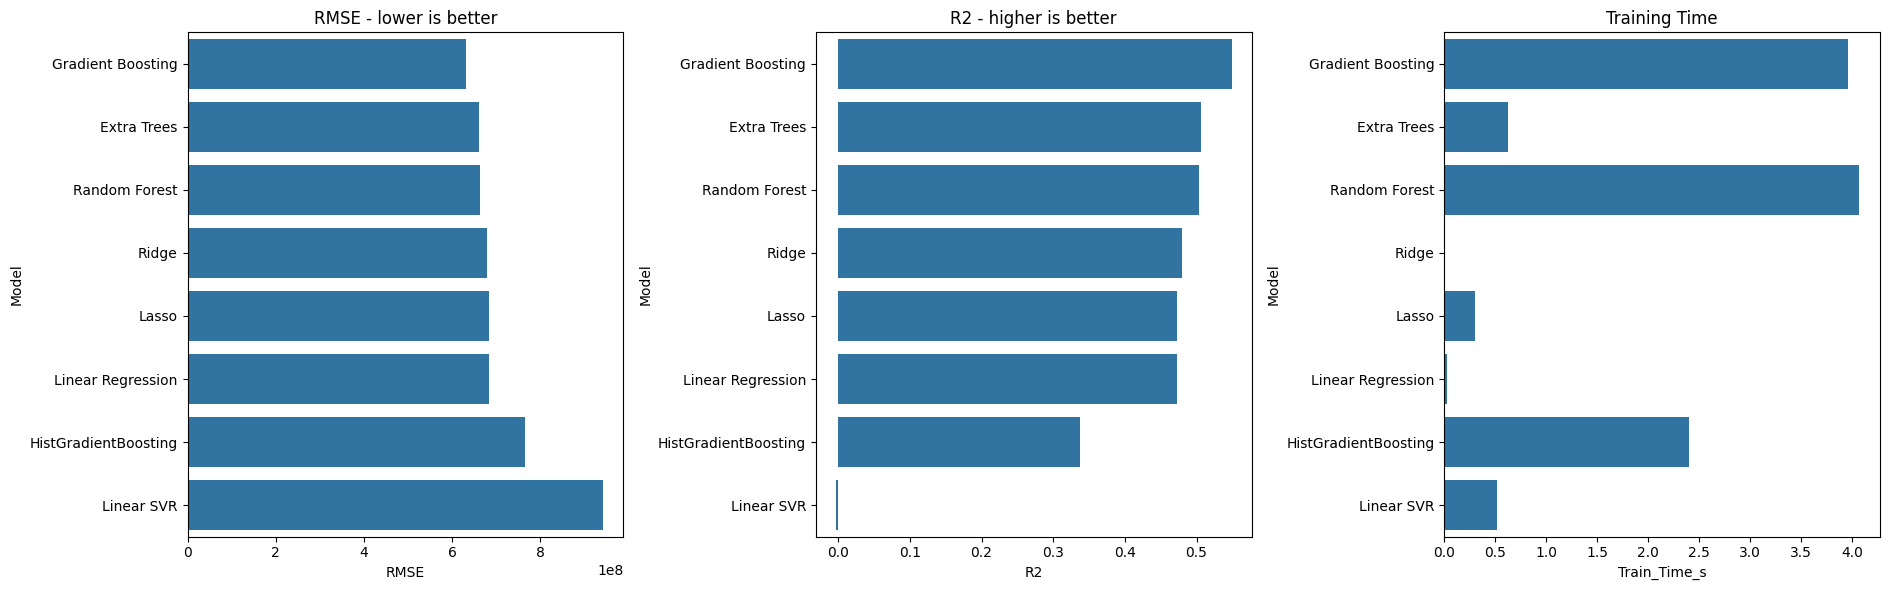

In [25]:
# Benchmark visualization
fig, axes = plt.subplots(1,3,figsize=(19,6))
sns.barplot(data=benchmark,x="RMSE",y="Model",ax=axes[0]); axes[0].set_title("RMSE - lower is better")
sns.barplot(data=benchmark,x="R2",y="Model",ax=axes[1]); axes[1].set_title("R2 - higher is better")
sns.barplot(data=benchmark,x="Train_Time_s",y="Model",ax=axes[2]); axes[2].set_title("Training Time")
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp6_benchmark.png",dpi=180)
plt.show()


# Experiment 07 — Model Development

**Model A — Ridge Regression:** transparent linear baseline, robust to multicollinearity.
**Model B — Random Forest Regressor:** captures non-linear interactions, provides model-based importance.

## Validation protocol
Earlier years → development, most recent development years → validation, final unseen years → test. The test set is not used to choose the model.


In [26]:
# ============================================================
# Validation period selection
# ============================================================
dev_years = sorted(train_data["crop_year"].unique())
val_years = dev_years[-max(1,min(2,len(dev_years)//4)):]

dev = train_data[~train_data["crop_year"].isin(val_years)]
val = train_data[train_data["crop_year"].isin(val_years)]

X_dev, y_dev = dev[feature_cols], dev["target_next_year_production"]
X_val, y_val = val[feature_cols], val["target_next_year_production"]

candidate = {"Ridge": models["Ridge"], "Random Forest": models["Random Forest"]}

rows=[]
for name, model in candidate.items():
    model.fit(X_dev,y_dev)
    pred=np.maximum(model.predict(X_val),0)
    rows.append({
        "Model":name,
        "Validation_MAE":mean_absolute_error(y_val,pred),
        "Validation_RMSE":mean_squared_error(y_val,pred)**0.5,
        "Validation_R2":r2_score(y_val,pred)
    })

validation_results=pd.DataFrame(rows).sort_values("Validation_RMSE")
display(validation_results)

selected_name=validation_results.iloc[0]["Model"]
selected_model=candidate[selected_name]
print("Validation-selected model:",selected_name)


,Model,Validation_MAE,Validation_RMSE,Validation_R2
1,Random Forest,1.208086e+07,1.902593e+08,0.966907
0,Ridge,1.345023e+07,1.977935e+08,0.964234


Validation-selected model: Random Forest


## Model development assumptions
1. Observations are ordered chronologically. 2. Target is next-year production. 3. Current-year predictors are assumed available at forecast time. 4. Lag/rolling variables use only past observations. 5. Missing values are imputed inside pipelines. 6. The final test period is never used for model selection. 7. A high predictive score does not imply causal influence.


# Experiment 08 — Model Evaluation and Validation

This forecasting task uses **TimeSeriesSplit**: each fold trains on earlier years and validates on later years. Metrics: MAE, RMSE, R², MAPE, fold mean ± SD, final independent test, residual distribution, crop-level errors.


In [27]:
# ============================================================
# Time-aware cross-validation
# ============================================================
cv_data = train_data.sort_values("crop_year").reset_index(drop=True)
X_cv = cv_data[feature_cols]
y_cv = cv_data["target_next_year_production"]

tscv = TimeSeriesSplit(n_splits=5)
cv_rows=[]
for fold,(tr_idx,va_idx) in enumerate(tscv.split(X_cv),1):
    model = candidate[selected_name]
    model.fit(X_cv.iloc[tr_idx],y_cv.iloc[tr_idx])
    pred=np.maximum(model.predict(X_cv.iloc[va_idx]),0)
    cv_rows.append({
        "Fold":fold,
        "Train_End_Year":cv_data.iloc[tr_idx]["crop_year"].max(),
        "Validation_Start_Year":cv_data.iloc[va_idx]["crop_year"].min(),
        "Validation_End_Year":cv_data.iloc[va_idx]["crop_year"].max(),
        "MAE":mean_absolute_error(y_cv.iloc[va_idx],pred),
        "RMSE":mean_squared_error(y_cv.iloc[va_idx],pred)**0.5,
        "R2":r2_score(y_cv.iloc[va_idx],pred)
    })

cv_results=pd.DataFrame(cv_rows)
display(cv_results)
for metric in ["MAE","RMSE","R2"]:
    print(metric, "mean +/- SD =", round(cv_results[metric].mean(),4), "+/-", round(cv_results[metric].std(),4))


,Fold,Train_End_Year,Validation_Start_Year,Validation_End_Year,MAE,RMSE,R2
0,1,2001,2001,2005,3.480393e+07,4.502544e+08,0.807958
1,2,2005,2005,2009,1.537798e+07,2.070958e+08,0.969274
2,3,2009,2009,2013,6.521494e+06,9.875888e+07,0.988166
3,4,2013,2013,2016,6.667783e+06,9.144315e+07,0.994542
4,5,2016,2016,2019,9.129667e+06,1.546199e+08,0.977223


MAE mean +/- SD = 14500170.5889 +/- 11904420.5524
RMSE mean +/- SD = 200434431.558 +/- 147284051.358
R2 mean +/- SD = 0.9474 +/- 0.0786


In [28]:
# ============================================================
# Final fit and independent test
# ============================================================
final_model = candidate[selected_name]
final_model.fit(X_train,y_train)
test_pred=np.maximum(final_model.predict(X_test),0)

final_metrics=pd.DataFrame([{
    "MAE":mean_absolute_error(y_test,test_pred),
    "RMSE":mean_squared_error(y_test,test_pred)**0.5,
    "R2":r2_score(y_test,test_pred),
    "MAPE":mean_absolute_percentage_error(y_test,np.maximum(y_test,1e-9))
}])
display(final_metrics)


,MAE,RMSE,R2,MAPE
0,3.794122e+07,6.628313e+08,0.502844,1.668000e+06


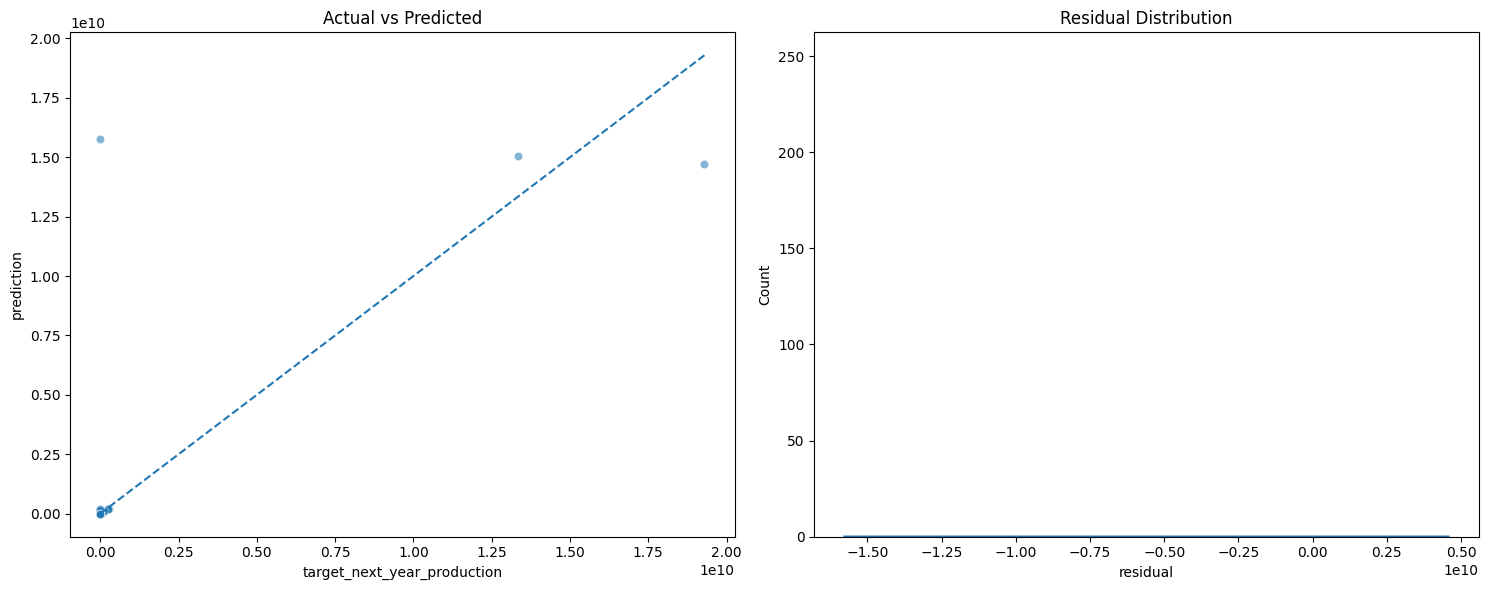

In [29]:
# Actual vs predicted and residuals
eval_df=test_data[["crop_year","crop","target_next_year_production"]].copy()
eval_df["prediction"]=test_pred
eval_df["residual"]=eval_df["target_next_year_production"]-eval_df["prediction"]
eval_df["absolute_error"]=eval_df["residual"].abs()

fig, axes=plt.subplots(1,2,figsize=(15,6))
sns.scatterplot(data=eval_df, x="target_next_year_production", y="prediction", alpha=.55, ax=axes[0])
lims=[min(eval_df["target_next_year_production"].min(),eval_df["prediction"].min()),
      max(eval_df["target_next_year_production"].max(),eval_df["prediction"].max())]
axes[0].plot(lims,lims,linestyle="--")
axes[0].set_title("Actual vs Predicted")
sns.histplot(eval_df["residual"],kde=True,ax=axes[1])
axes[1].set_title("Residual Distribution")
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp8_evaluation.png",dpi=180)
plt.show()


# Experiment 09 — Model Interpretation and Result Analysis

Interpretation uses permutation importance, feature-group interpretation, crop-level MAE, residual bias and worst-case analysis. A feature can be highly predictive without being causal.


,Feature,Importance_Mean,Importance_SD
6,area_growth,9.007929e+06,5.898364e+06
9,crop_year,0.000000e+00,5.331201e-08
7,yield_growth,-5.348298e+06,5.271757e+06
0,area,-6.221735e+06,6.842965e+06
4,area_lag_1,-2.056939e+07,2.341336e+07
5,yield_lag_1,-3.869008e+07,2.740772e+06
3,production_lag_2,-4.162867e+07,2.925727e+05
8,production_roll_mean_3,-4.686468e+07,1.676812e+06
2,production_lag_1,-5.228008e+07,2.326907e+06
1,yield_per_ha,-5.556594e+07,6.620534e+05


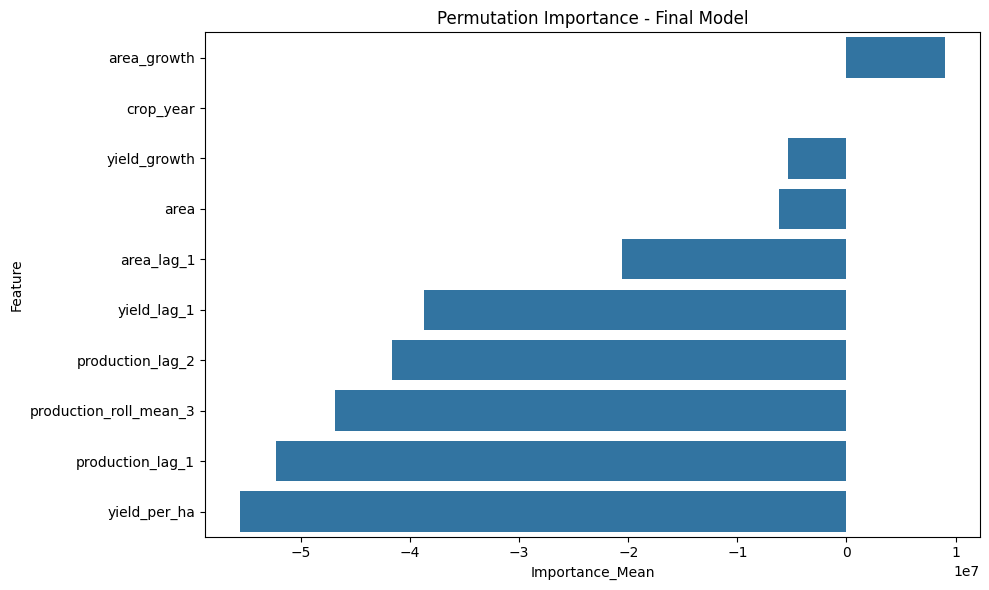

In [30]:
# Permutation importance
perm=permutation_importance(final_model,X_test,y_test, n_repeats=10,random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
importance=pd.DataFrame({
    "Feature":feature_cols,
    "Importance_Mean":perm.importances_mean,
    "Importance_SD":perm.importances_std
}).sort_values("Importance_Mean",ascending=False)
display(importance)

plt.figure(figsize=(10,6))
sns.barplot(data=importance.head(15),x="Importance_Mean",y="Feature")
plt.title("Permutation Importance - Final Model")
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp9_importance.png",dpi=180)
plt.show()


In [31]:
# Crop-level error analysis
crop_errors=(
    eval_df.groupby("crop",as_index=False)
           .agg(MAE=("absolute_error","mean"), Mean_Error=("residual","mean"), Observations=("residual","size"))
           .sort_values("MAE",ascending=False)
)
display(crop_errors.head(20))
print("Worst individual forecast cases:")
display(eval_df.sort_values("absolute_error",ascending=False).head(20))


,crop,MAE,Mean_Error,Observations
10,Coconut,7.352391e+09,-4.300815e+09,3
48,Sugarcane,5.136259e+07,-1.613992e+07,12
42,Rice,1.756571e+07,-1.728734e+07,18
55,Wheat,9.854530e+06,-9.325426e+06,14
12,Cotton(Lint),3.864178e+06,-3.554281e+06,12
39,Potato,3.680375e+06,-1.853231e+06,18
26,Maize,3.465907e+06,-3.171896e+06,21
47,Soyabean,2.427574e+06,-6.891662e+05,11
23,Jute,1.722093e+06,-1.707968e+06,6
4,Banana,1.656800e+06,-1.653998e+06,9


Worst individual forecast cases:


,crop_year,crop,target_next_year_production,prediction,residual,absolute_error
4671,2022,Coconut,0.000000e+00,1.577442e+10,-1.577442e+10,1.577442e+10
4463,2021,Coconut,1.929430e+10,1.471693e+10,4.577364e+09,4.577364e+09
4259,2020,Coconut,1.334744e+10,1.505283e+10,-1.705388e+09,1.705388e+09
4817,2022,Sugarcane,0.000000e+00,2.020288e+08,-2.020288e+08,2.020288e+08
4816,2022,Sugarcane,0.000000e+00,1.977376e+08,-1.977376e+08,1.977376e+08
4848,2022,Wheat,0.000000e+00,1.342513e+08,-1.342513e+08,1.342513e+08
4793,2022,Rice,0.000000e+00,1.106952e+08,-1.106952e+08,1.106952e+08
4790,2022,Rice,0.000000e+00,1.010744e+08,-1.010744e+08,1.010744e+08
4404,2020,Sugarcane,2.804031e+08,2.003467e+08,8.005640e+07,8.005640e+07
4606,2021,Sugarcane,2.634851e+08,2.048147e+08,5.867044e+07,5.867044e+07


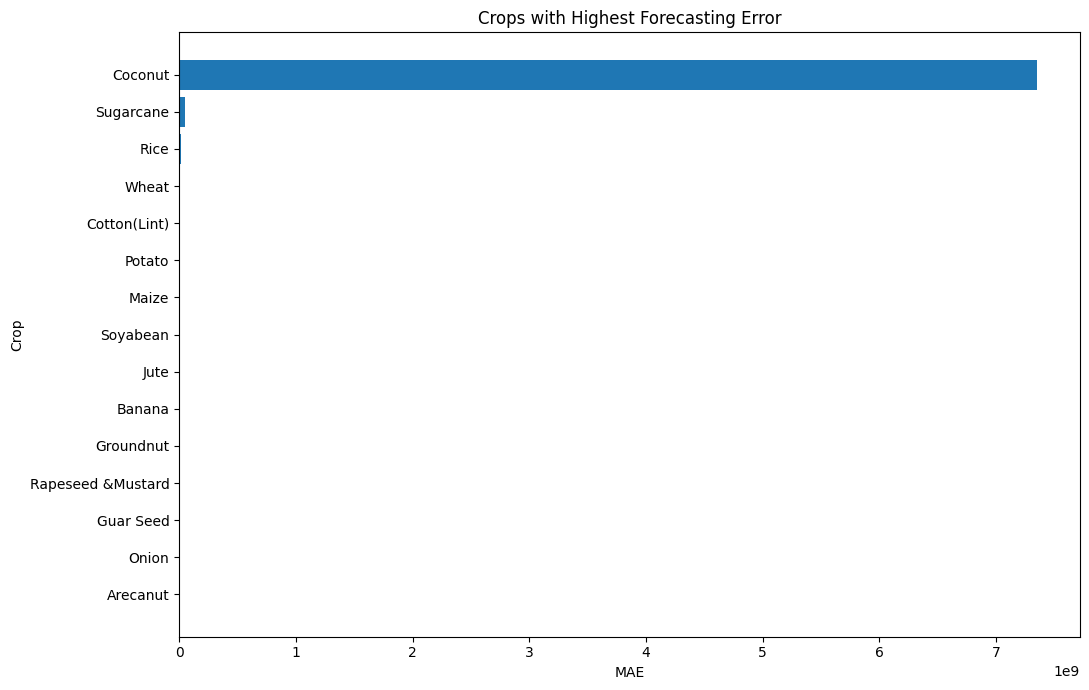

In [32]:
# Error bias visualization
top_error_crops=crop_errors.head(15).sort_values("MAE")
plt.figure(figsize=(11,7))
plt.barh(top_error_crops["crop"],top_error_crops["MAE"])
plt.xlabel("MAE"); plt.ylabel("Crop")
plt.title("Crops with Highest Forecasting Error")
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp9_crop_errors.png",dpi=180)
plt.show()


# Experiment 10 — Real-World Business Problem Solving with Data Analytics

### KPIs
Production planning, forecast risk, productivity monitoring, resource prioritization.

### Decision matrix
A monitoring priority score combines forecasting error (risk) with production scale, producing high/medium/low priority actions per crop.


In [33]:
# ============================================================
# Business decision matrix
# ============================================================
decision=eval_df.groupby("crop",as_index=False).agg(
    mean_actual=("target_next_year_production","mean"),
    mean_prediction=("prediction","mean"),
    MAE=("absolute_error","mean"),
    mean_error=("residual","mean"),
    observations=("crop","size")
)

def minmax(s):
    if s.max()==s.min():
        return pd.Series(np.zeros(len(s)),index=s.index)
    return (s-s.min())/(s.max()-s.min())

decision["error_risk"]=minmax(decision["MAE"])
decision["production_scale"]=minmax(decision["mean_actual"])
decision["priority_score"]=0.6*decision["error_risk"]+0.4*decision["production_scale"]
decision["action"]=np.select(
    [decision["priority_score"]>=.75, decision["priority_score"]>=.45],
    ["High priority - investigate and monitor","Medium priority - periodic review"],
    default="Low priority - routine monitoring"
)
decision=decision.sort_values("priority_score",ascending=False)
display(decision.head(20))


,crop,mean_actual,mean_prediction,MAE,mean_error,observations,error_risk,production_scale,priority_score,action
10,Coconut,1.088058e+10,1.518139e+10,7.352391e+09,-4.300815e+09,3,1.000000,1.000000,1.000000,High priority - investigate and monitor
48,Sugarcane,8.515641e+07,1.012963e+08,5.136259e+07,-1.613992e+07,12,0.006986,0.007826,0.007322,Low priority - routine monitoring
42,Rice,2.506855e+07,4.235589e+07,1.756571e+07,-1.728734e+07,18,0.002389,0.002304,0.002355,Low priority - routine monitoring
55,Wheat,1.804421e+07,2.736964e+07,9.854530e+06,-9.325426e+06,14,0.001340,0.001658,0.001467,Low priority - routine monitoring
12,Cotton(Lint),5.488593e+06,9.042874e+06,3.864178e+06,-3.554281e+06,12,0.000525,0.000504,0.000517,Low priority - routine monitoring
39,Potato,5.428846e+06,7.282077e+06,3.680375e+06,-1.853231e+06,18,0.000500,0.000499,0.000500,Low priority - routine monitoring
26,Maize,5.873307e+06,9.045203e+06,3.465907e+06,-3.171896e+06,21,0.000471,0.000540,0.000499,Low priority - routine monitoring
47,Soyabean,3.230622e+06,3.919788e+06,2.427574e+06,-6.891662e+05,11,0.000330,0.000297,0.000317,Low priority - routine monitoring
23,Jute,3.111931e+06,4.819899e+06,1.722093e+06,-1.707968e+06,6,0.000234,0.000286,0.000255,Low priority - routine monitoring
4,Banana,1.979456e+06,3.633454e+06,1.656800e+06,-1.653998e+06,9,0.000225,0.000182,0.000208,Low priority - routine monitoring


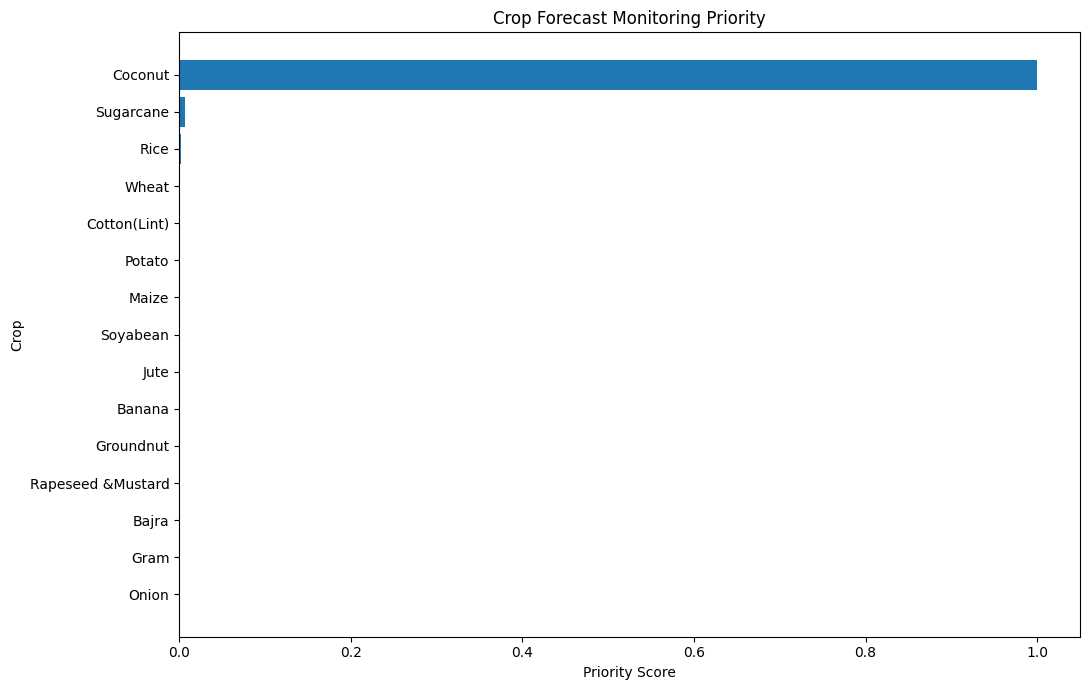

In [34]:
# Business priority visualization
plot_decision=decision.head(15).sort_values("priority_score")
plt.figure(figsize=(11,7))
plt.barh(plot_decision["crop"],plot_decision["priority_score"])
plt.xlabel("Priority Score"); plt.ylabel("Crop")
plt.title("Crop Forecast Monitoring Priority")
plt.tight_layout()
plt.savefig(REPORT_DIR / "exp10_decision_matrix.png",dpi=180)
plt.show()


# Additional Analysis — Feature Ablation Study

Compares progressively richer feature sets. With this single-source dataset, price/weather groups are typically empty, so the baseline is the primary set. If richer sets are unavailable the study reports the baseline only.


Actual baseline features: ['area', 'yield_per_ha', 'production_lag_1', 'production_lag_2', 'area_lag_1', 'yield_lag_1', 'area_growth', 'yield_growth', 'production_roll_mean_3', 'crop_year']
Actual price features: []
Actual weather features: []


,Feature_Set,MAE,RMSE,R2
0,Baseline,3.794122e+07,6.628313e+08,0.502844
1,Baseline + Price,3.794122e+07,6.628313e+08,0.502844
2,Baseline + Price + Weather,3.794122e+07,6.628313e+08,0.502844


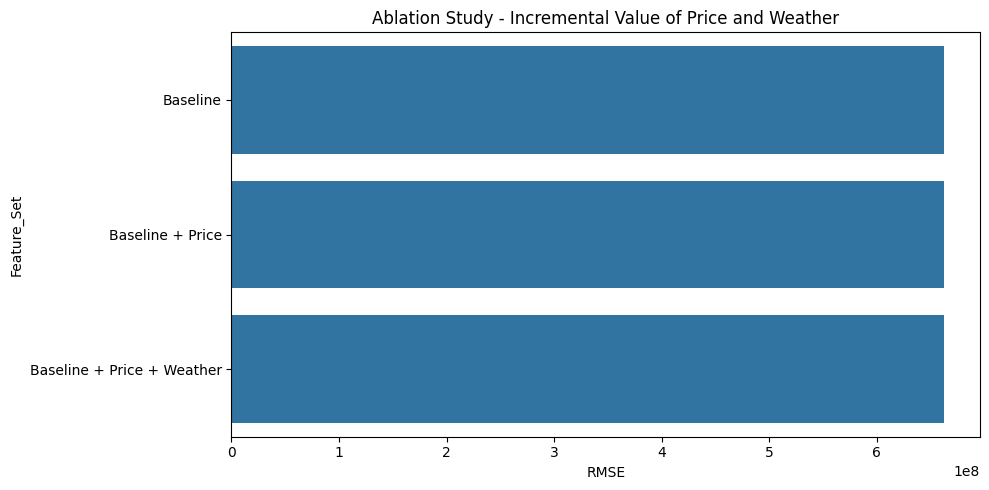

In [35]:
# ============================================================
# Ablation study using the selected model
# ============================================================
baseline_features = [
    "area", "yield_per_ha", "production_lag_1", "production_lag_2",
    "area_lag_1", "yield_lag_1", "area_growth", "yield_growth",
    "production_roll_mean_3", "crop_year"
]
price_features = ["price_indicator", "price_growth"]
weather_features_available = ["rainfall", "temperature", "humidity", "wind_speed", "solar_radiation"]

actual_baseline_features = [c for c in baseline_features if c in forecast.columns]
actual_price_features = [c for c in price_features if c in forecast.columns]
actual_weather_features = [c for c in weather_features_available if c in forecast.columns]

print("Actual baseline features:", actual_baseline_features)
print("Actual price features:", actual_price_features)
print("Actual weather features:", actual_weather_features)

def evaluate_feature_set(feature_set, label):
    feature_set = [c for c in feature_set if c in forecast.columns]
    if len(feature_set) < 2:
        print(f"Skipping {label}: fewer than 2 available features.")
        return None
    model = candidate[selected_name]
    model.fit(train_data[feature_set], y_train)
    pred = np.maximum(model.predict(test_data[feature_set]), 0)
    return {
        "Feature_Set": label,
        "Features": ", ".join(feature_set),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred)**0.5,
        "R2": r2_score(y_test, pred)
    }

ablation_rows = [
    evaluate_feature_set(actual_baseline_features, "Baseline"),
    evaluate_feature_set(actual_baseline_features + actual_price_features, "Baseline + Price"),
    evaluate_feature_set(actual_baseline_features + actual_price_features + actual_weather_features, "Baseline + Price + Weather")
]
ablation_results = pd.DataFrame([r for r in ablation_rows if r is not None])
display(ablation_results[["Feature_Set", "MAE", "RMSE", "R2"]])

if not ablation_results.empty:
    plt.figure(figsize=(10,5))
    sns.barplot(data=ablation_results, x="RMSE", y="Feature_Set")
    plt.title("Ablation Study - Incremental Value of Price and Weather")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / "ablation_study.png", dpi=180)
    plt.show()


# Final Results & Project Conclusion

**Data acquisition** → local CSV load → schema audit → production/area/yield master table.
**Analytics** → descriptive statistics → trends → crop/state comparisons → correlations → outliers → hypothesis testing.
**Feature engineering** → lagged production → area/yield growth → rolling statistics → mutual information → PCA.
**Machine learning** → 8-model benchmark → validation-based selection → TimeSeriesSplit → independent future-period evaluation → permutation importance → residual/crop error analysis.
**Business intelligence** → crop monitoring priorities → production planning insights → limitations → recommendations.

## Final reporting rule
Run the notebook first and replace any placeholder narrative with the actual generated values.

## Main limitations
1. Area and production are mechanically related, so importance is not causal. 2. A single source means no external price/weather validation. 3. Historical data cannot capture future structural breaks. 4. MAPE is unstable near zero production; MAE/RMSE are primary. 5. A time-aware split is essential to avoid leakage.


# Reproducibility & Submission Checklist

- [ ] Local CSV present next to the notebook.
- [ ] Dataset inventory checked.
- [ ] Missing values and duplicates checked.
- [ ] Yield validated/calculated.
- [ ] All EDA figures generated.
- [ ] Hypothesis tests completed.
- [ ] Feature selection/PCA completed.
- [ ] Eight-model benchmark completed.
- [ ] Ridge vs Random Forest validation completed.
- [ ] TimeSeriesSplit completed.
- [ ] Independent test metrics recorded.
- [ ] Feature importance and crop error analysis completed.
- [ ] Decision matrix generated.
- [ ] Final report (DOCX) generated.


In [36]:
# ================================================================
# VERIFY ALL GENERATED FIGURES
# ================================================================
image_extensions = {".png", ".jpg", ".jpeg", ".webp"}
all_images = sorted(
    [p for p in REPORT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in image_extensions],
    key=lambda p: p.name.lower()
)
print("="*70)
print("ALL GENERATED FIGURES")
print("="*70)
print(f"Location: {REPORT_DIR}")
print(f"Total images found: {len(all_images)}")
print()
for i, img in enumerate(all_images, 1):
    print(f"{i:02d}. {img.name}")


ALL GENERATED FIGURES
Location: C:\Users\SAMSUNG\Desktop\DA\project\report_outputs
Total images found: 14

01. ablation_study.png
02. exp10_decision_matrix.png
03. exp3_correlation.png
04. exp3_national_trend.png
05. exp3_top_crop_trends.png
06. exp3_univariate.png
07. exp4_mutual_information.png
08. exp4_pca.png
09. exp5_correlation.png
10. exp5_dashboard.png
11. exp6_benchmark.png
12. exp8_evaluation.png
13. exp9_crop_errors.png
14. exp9_importance.png


# Supplementary Analysis — Ensure 3+ Figures per Experiment

The following cell adds extra figures where an experiment has fewer than three, using variables already created above. It does not retrain models or reload data.


SUPPLEMENTARY ANALYSIS - 3 FIGURES PER EXPERIMENT

== EXPERIMENT 1 ==


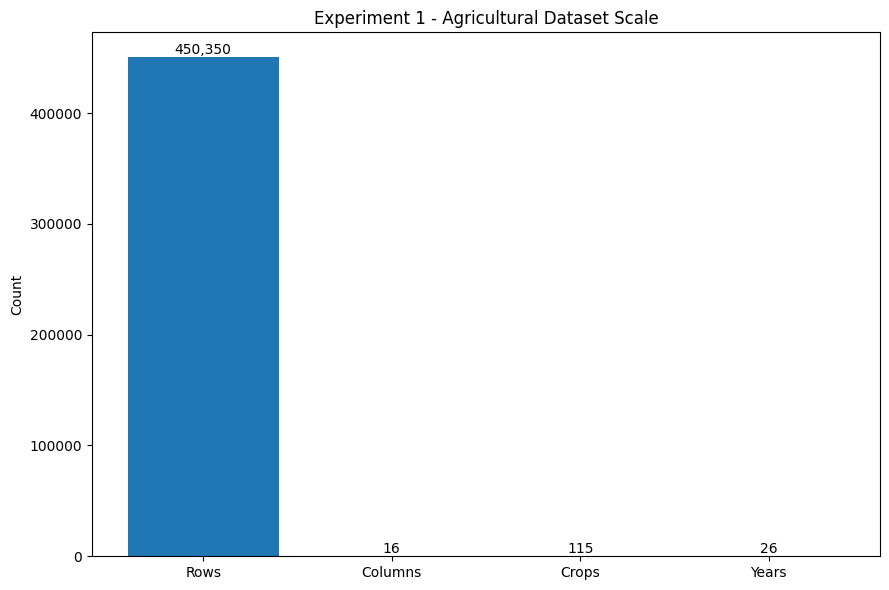

Created: exp1_dataset_scale.png


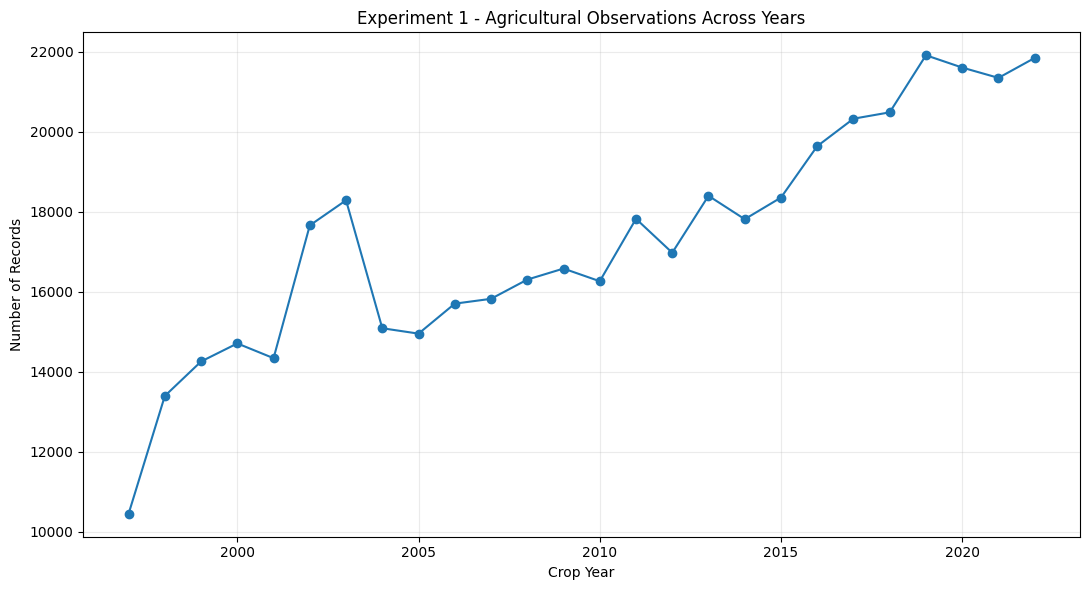

Created: exp1_yearly_observations.png


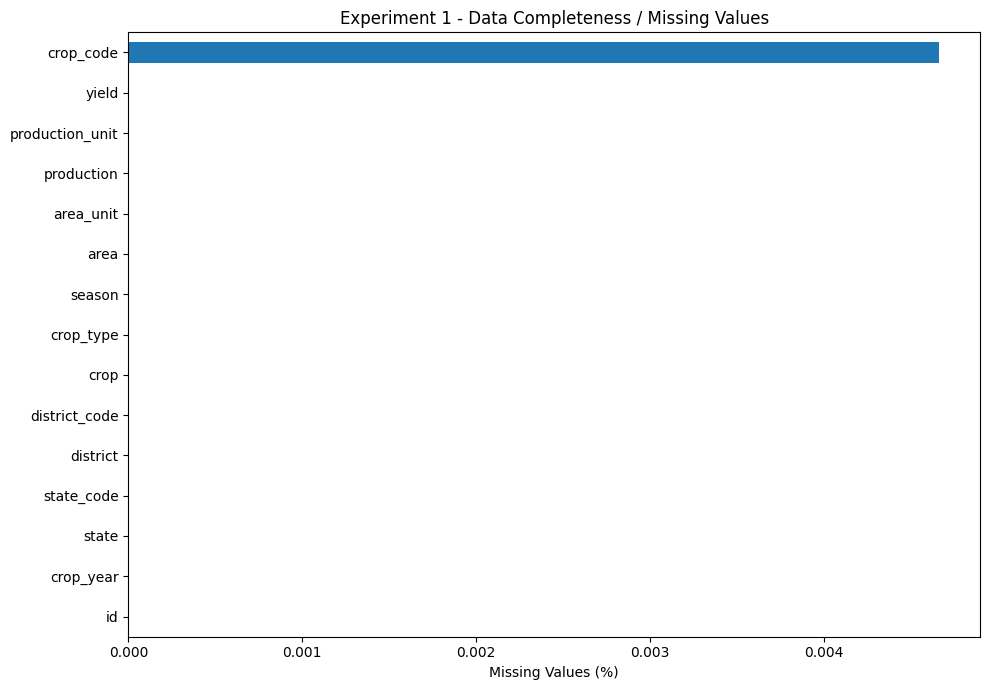

Created: exp1_data_completeness.png

== EXPERIMENT 2 ==


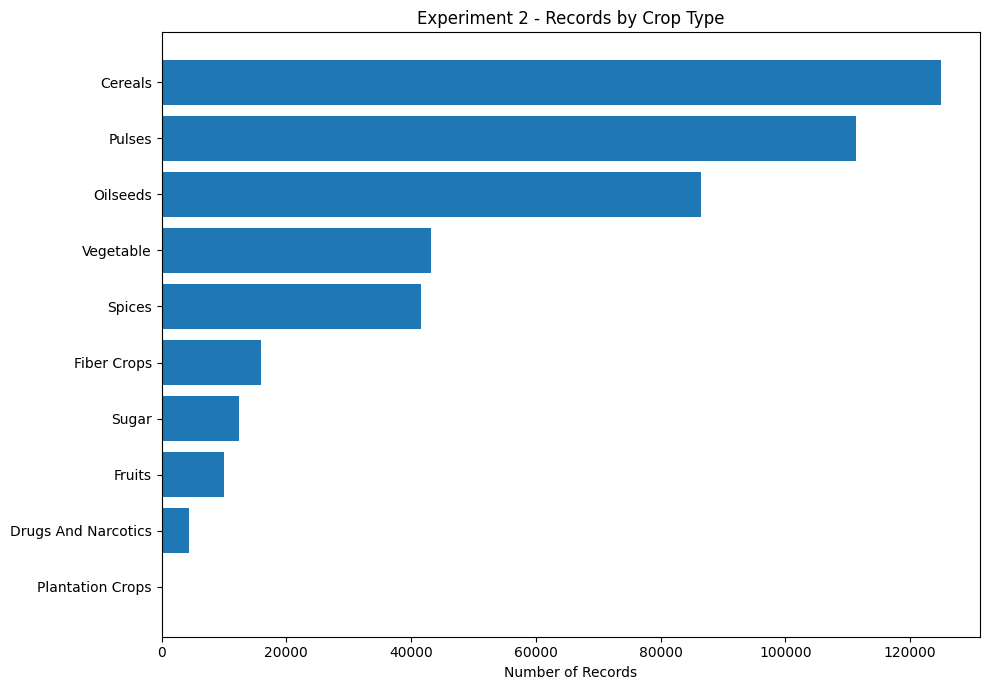

Created: exp2_crop_type_composition.png


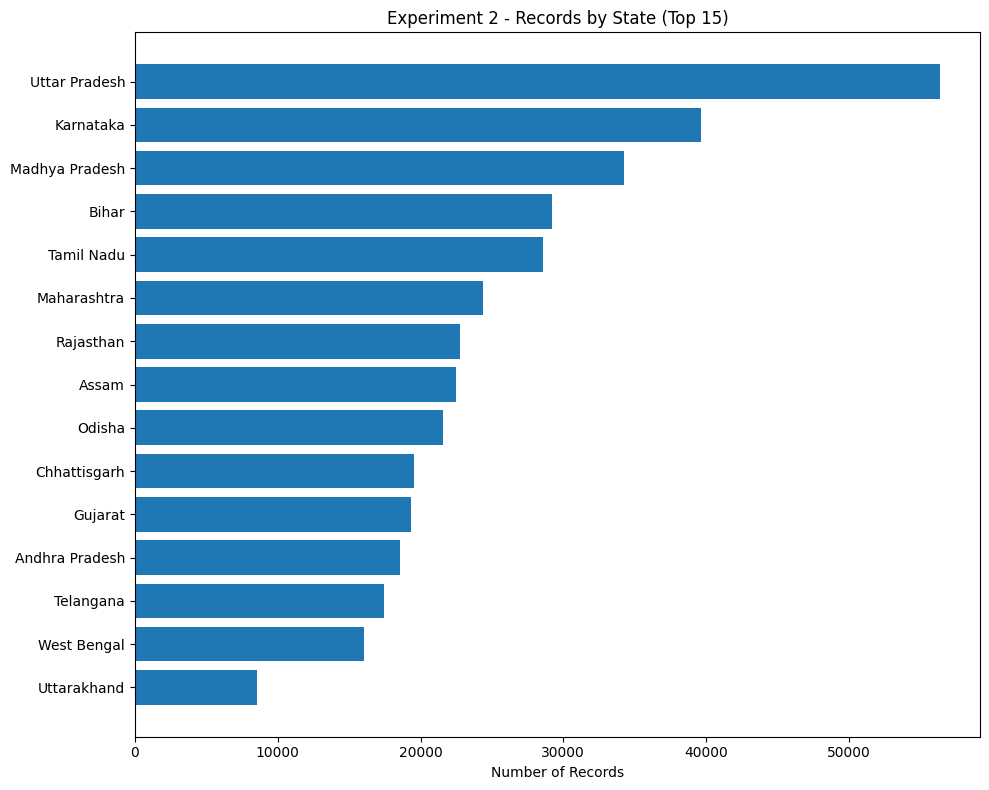

Created: exp2_state_coverage.png


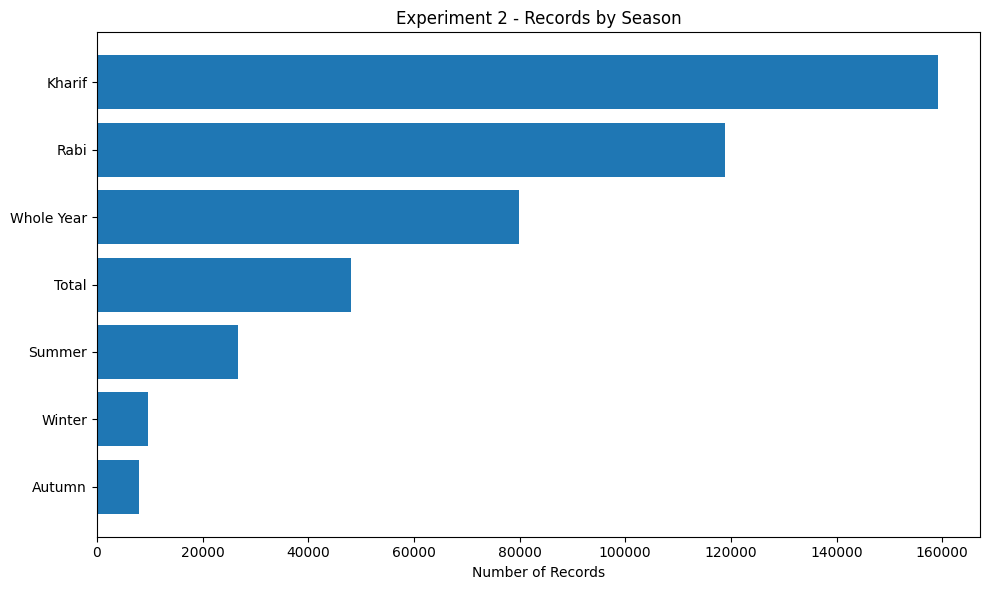

Created: exp2_season_coverage.png

== EXPERIMENT 3 ==
Experiment 3 already has 4 figures.

== EXPERIMENT 4 ==


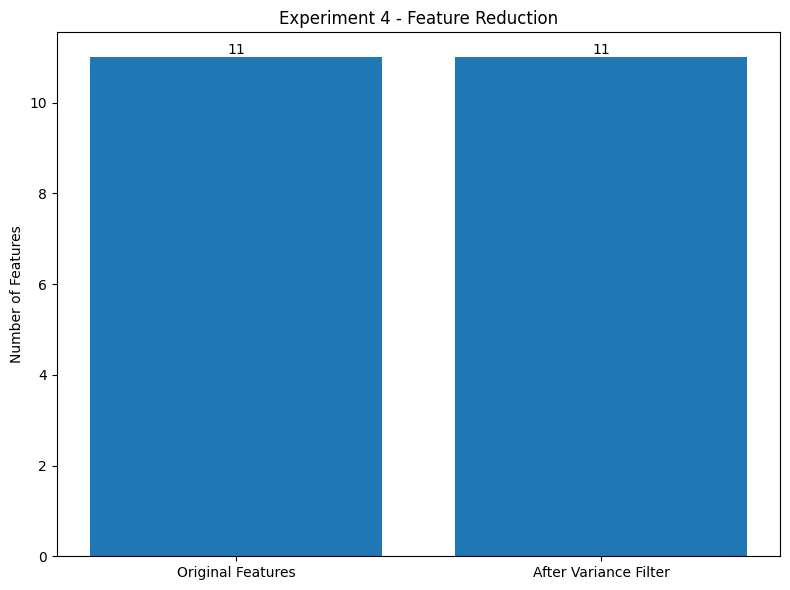

Created: exp4_feature_reduction.png

== EXPERIMENT 5 ==


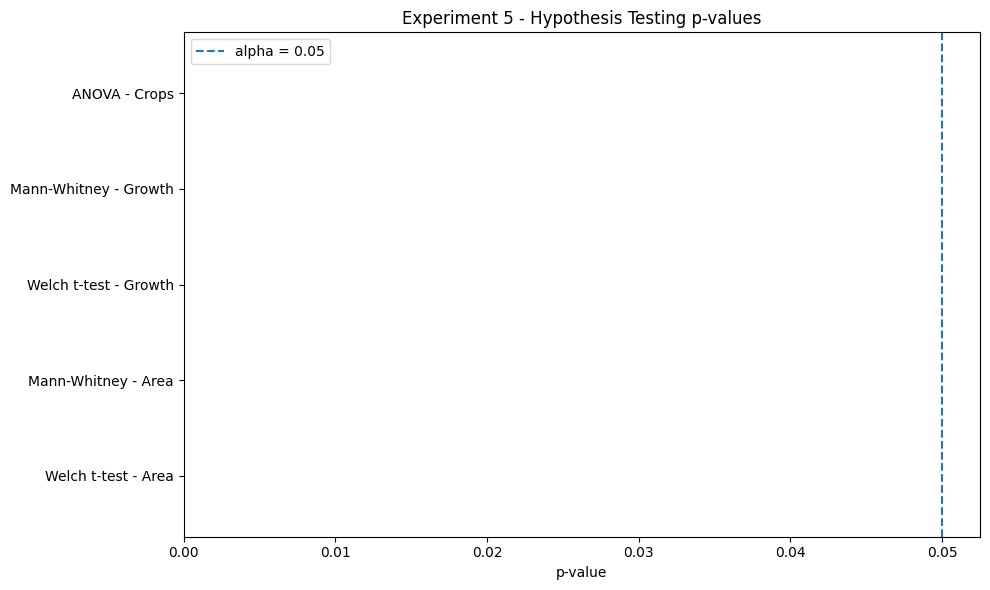

Created: exp5_hypothesis_tests.png

== EXPERIMENT 6 ==


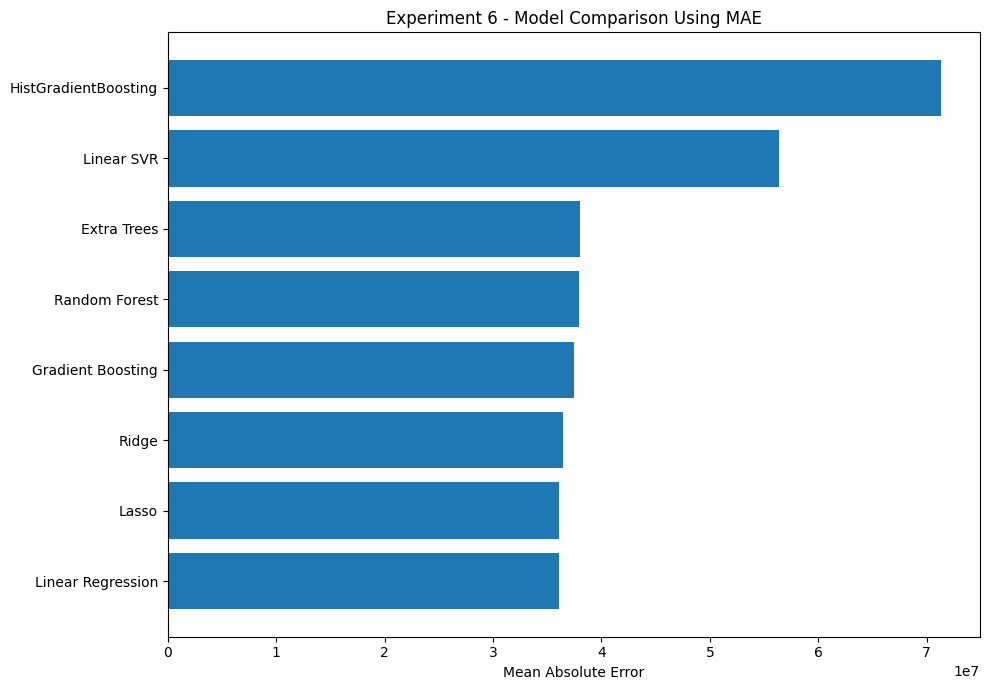

Created: exp6_mae_comparison.png


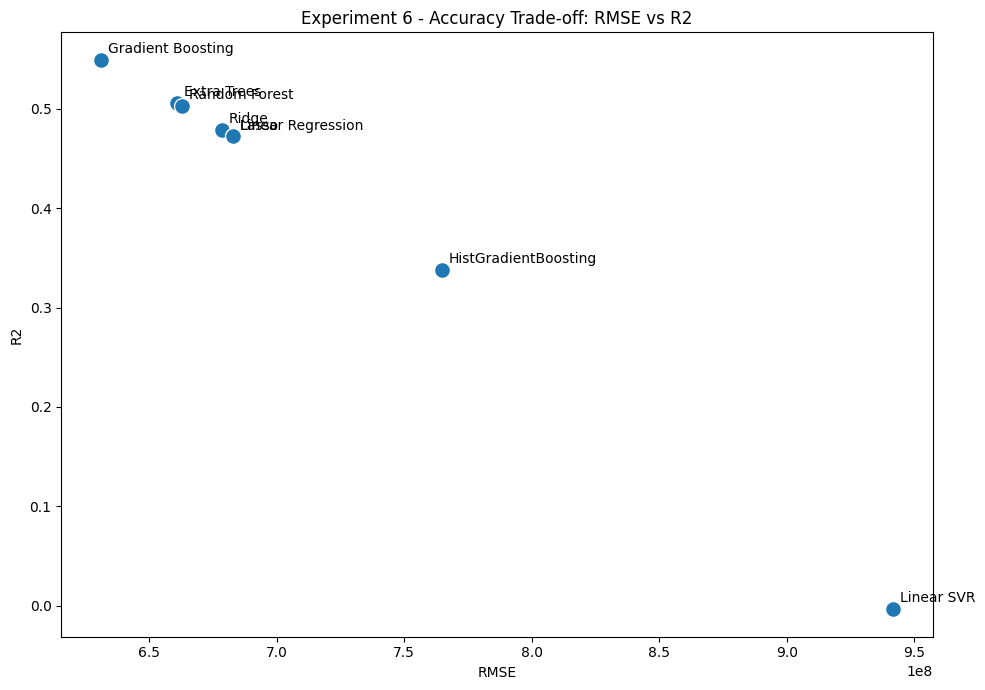

Created: exp6_rmse_r2_tradeoff.png

== EXPERIMENT 7 ==


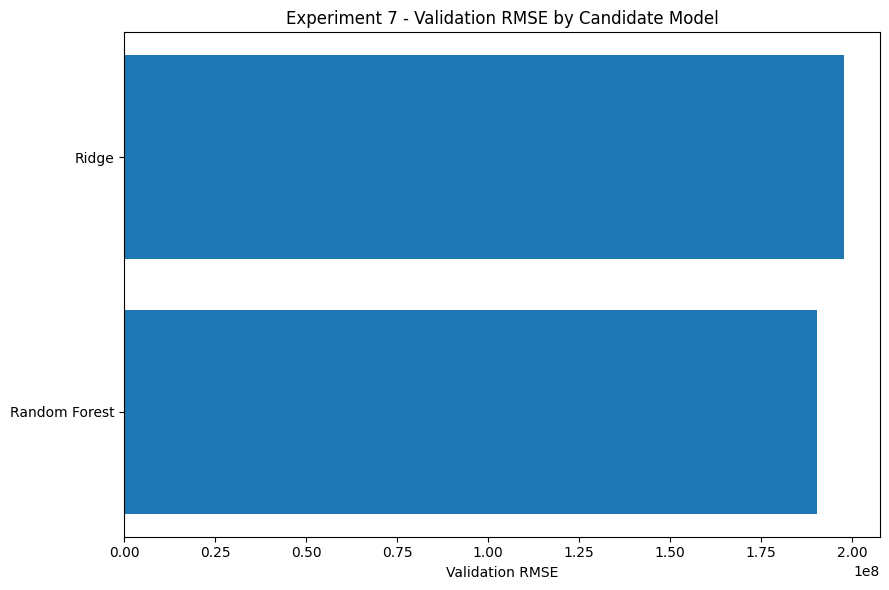

Created: exp7_validation_rmse.png


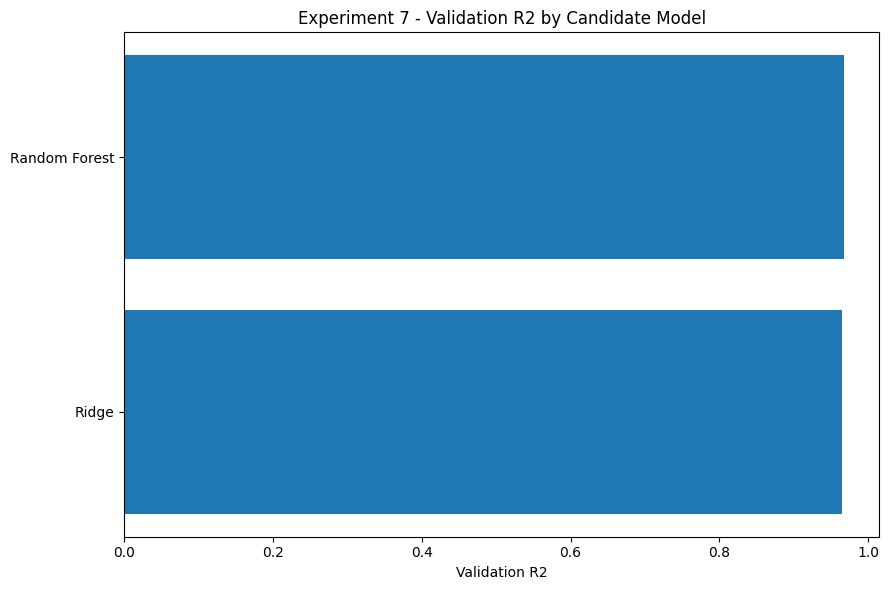

Created: exp7_validation_r2.png


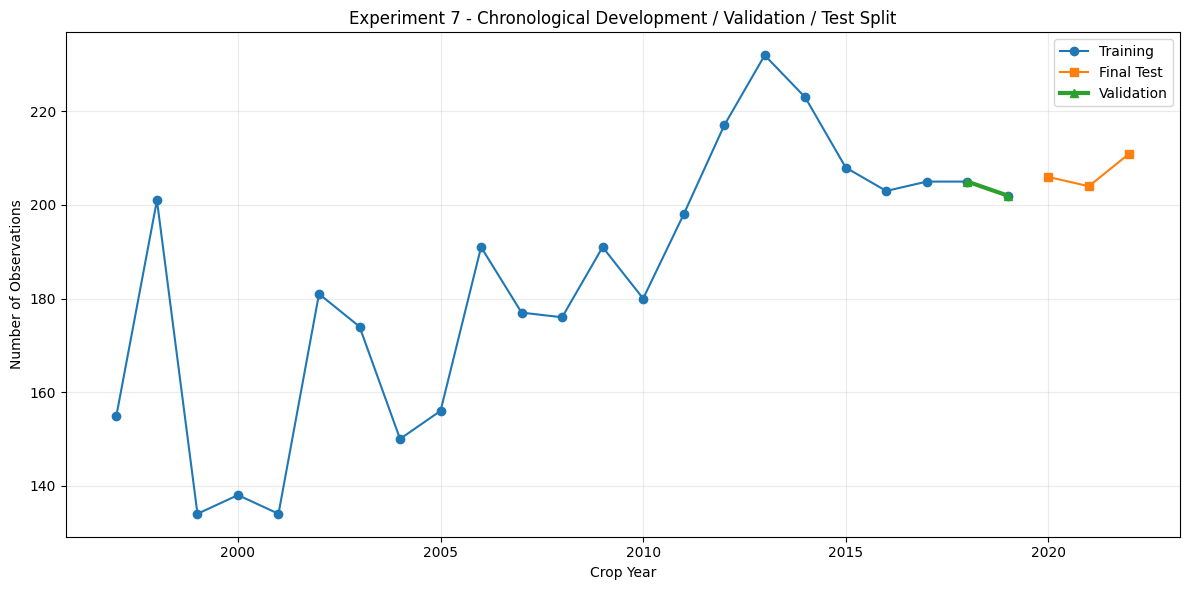

Created: exp7_chronological_split.png

== EXPERIMENT 8 ==


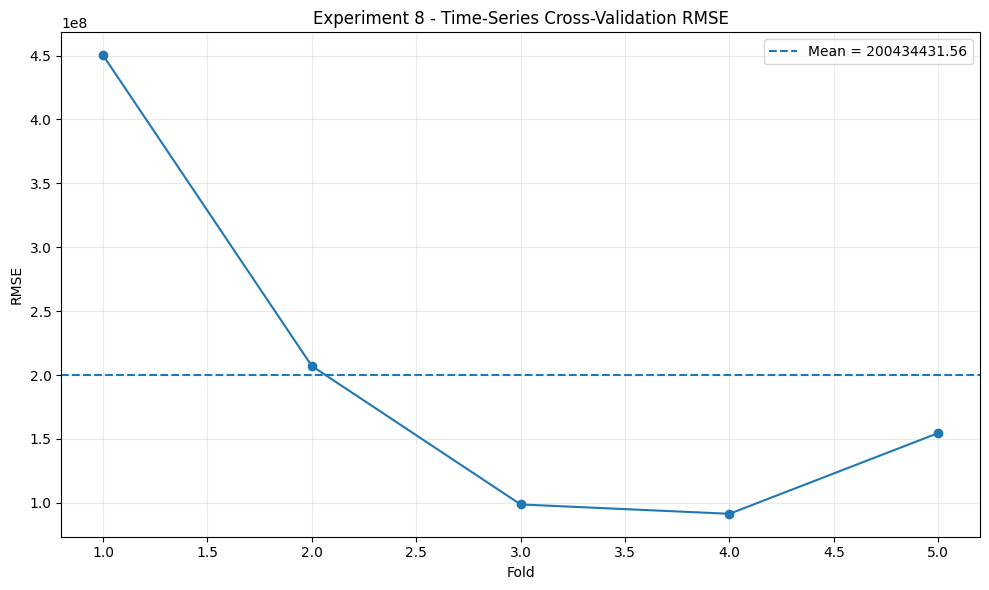

Created: exp8_cv_rmse.png


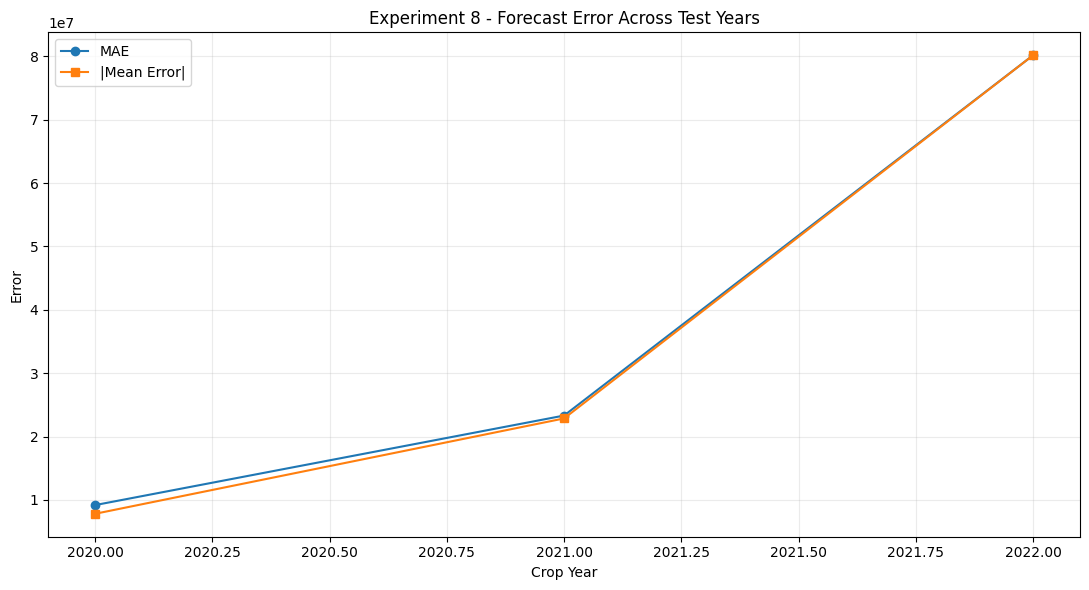

Created: exp8_error_by_year.png

== EXPERIMENT 9 ==


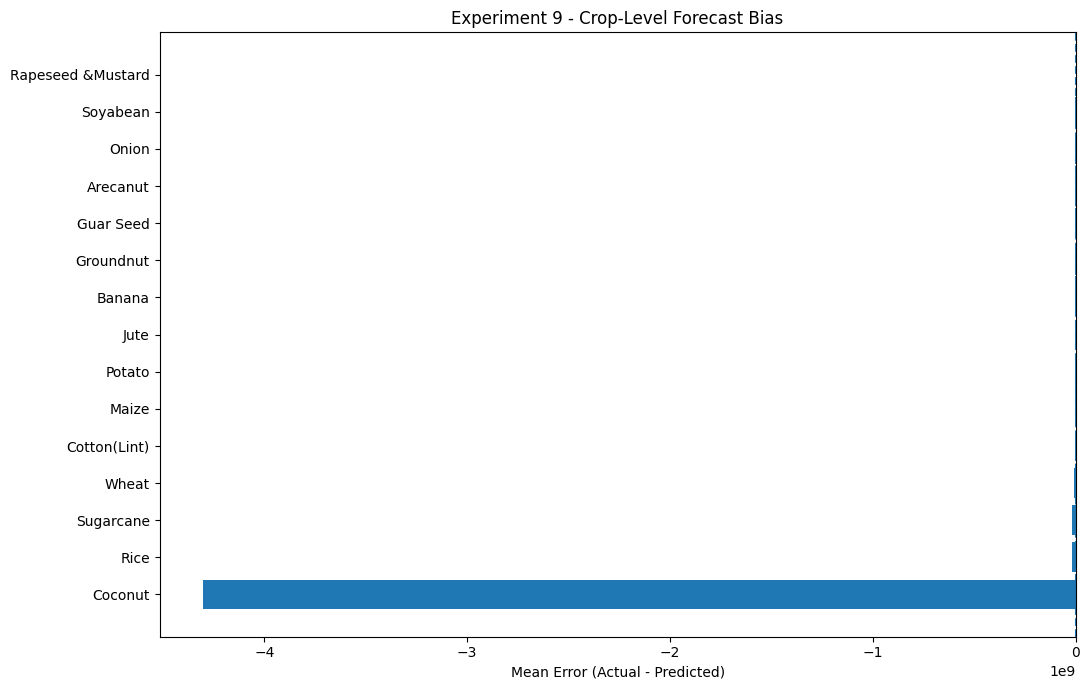

Created: exp9_crop_bias.png

== EXPERIMENT 10 ==


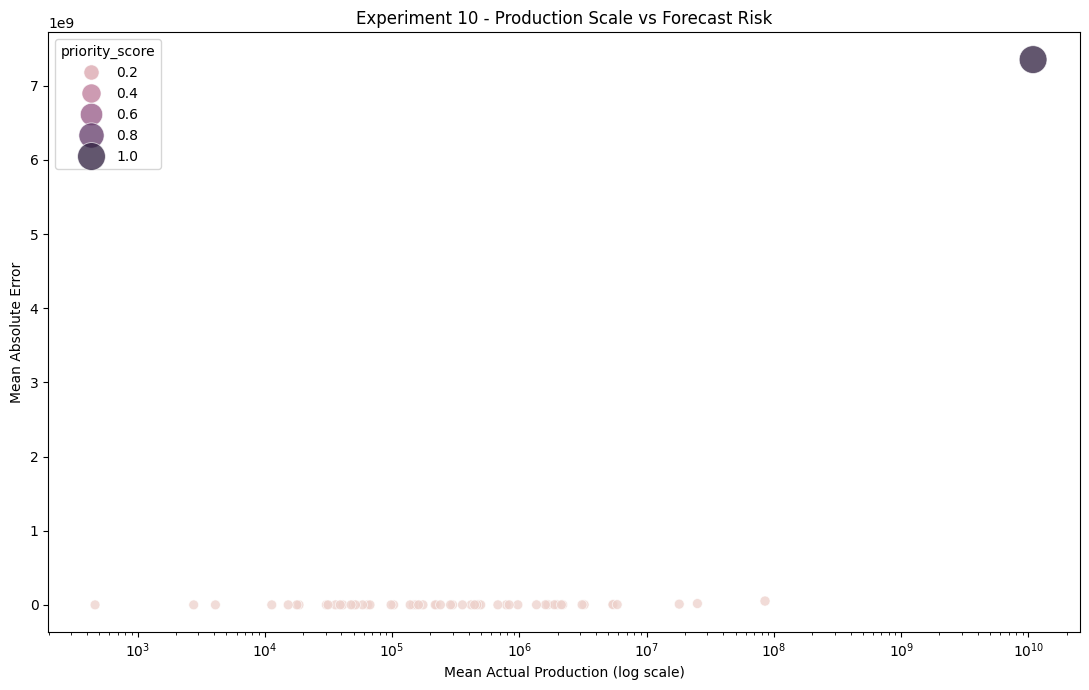

Created: exp10_production_vs_forecast_risk.png

FINAL FIGURE COUNT
Experiment 01: 3 figure(s)
Experiment 02: 3 figure(s)
Experiment 03: 4 figure(s)
Experiment 04: 3 figure(s)
Experiment 05: 3 figure(s)
Experiment 06: 3 figure(s)
Experiment 07: 3 figure(s)
Experiment 08: 3 figure(s)
Experiment 09: 3 figure(s)
Experiment 10: 3 figure(s)

TOTAL FIGURES: 31
Supplementary analysis complete.


In [37]:
# ================================================================
# SUPPLEMENTARY ANALYSIS - ENSURE 3+ FIGURES PER EXPERIMENT
# ================================================================
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print("="*75)
print("SUPPLEMENTARY ANALYSIS - 3 FIGURES PER EXPERIMENT")
print("="*75)

def save_fig(filename):
    path = REPORT_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Created:", filename)

def existing_experiment_images(exp_no):
    extensions = {".png", ".jpg", ".jpeg", ".webp"}
    files = [p for p in REPORT_DIR.iterdir()
             if p.is_file() and p.suffix.lower() in extensions
             and (f"exp{exp_no}_" in p.name.lower() or f"exp{exp_no}." in p.name.lower() or f"experiment_{exp_no}" in p.name.lower())]
    if exp_no == 10:
        files += [p for p in REPORT_DIR.iterdir() if p.name.lower() == "ablation_study.png"]
    return sorted(set(files))

# ---------------- EXPERIMENT 1 ----------------
print("\n== EXPERIMENT 1 ==")
if "df" in globals():
    fig, ax = plt.subplots(figsize=(9, 6))
    values = {
        "Rows": len(df),
        "Columns": len(df.columns),
        "Crops": df["crop"].nunique() if "crop" in df.columns else 0,
        "Years": df["crop_year"].nunique() if "crop_year" in df.columns else 0
    }
    ax.bar(list(values.keys()), list(values.values()))
    ax.set_title("Experiment 1 - Agricultural Dataset Scale")
    ax.set_ylabel("Count")
    for i, value in enumerate(values.values()):
        ax.text(i, value, f"{value:,}", ha="center", va="bottom")
    save_fig("exp1_dataset_scale.png")

if "df" in globals() and "crop_year" in df.columns:
    yearly_records = df.groupby("crop_year").size().reset_index(name="observations")
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(yearly_records["crop_year"], yearly_records["observations"], marker="o")
    ax.set_title("Experiment 1 - Agricultural Observations Across Years")
    ax.set_xlabel("Crop Year"); ax.set_ylabel("Number of Records"); ax.grid(alpha=0.25)
    save_fig("exp1_yearly_observations.png")

if "df" in globals():
    missing_pct = df.isna().mean().mul(100).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(10, 7))
    missing_pct.head(15).sort_values().plot(kind="barh", ax=ax)
    ax.set_title("Experiment 1 - Data Completeness / Missing Values")
    ax.set_xlabel("Missing Values (%)")
    save_fig("exp1_data_completeness.png")

# ---------------- EXPERIMENT 2 ----------------
print("\n== EXPERIMENT 2 ==")
if "df" in globals():
    # Figure 1: crop-type composition (uses this CSV's crop_type if present)
    if "crop_type" in df.columns:
        ct = df["crop_type"].value_counts().head(12).sort_values()
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.barh(ct.index.astype(str), ct.values)
        ax.set_title("Experiment 2 - Records by Crop Type")
        ax.set_xlabel("Number of Records")
        save_fig("exp2_crop_type_composition.png")
    # Figure 2: records per state (top 15)
    if "state" in df.columns:
        st = df["state"].value_counts().head(15).sort_values()
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.barh(st.index.astype(str), st.values)
        ax.set_title("Experiment 2 - Records by State (Top 15)")
        ax.set_xlabel("Number of Records")
        save_fig("exp2_state_coverage.png")
    # Figure 3: records per season
    if "season" in df.columns:
        se = df["season"].value_counts().sort_values()
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.barh(se.index.astype(str), se.values)
        ax.set_title("Experiment 2 - Records by Season")
        ax.set_xlabel("Number of Records")
        save_fig("exp2_season_coverage.png")

# ---------------- EXPERIMENT 3 ----------------
print("\n== EXPERIMENT 3 ==")
print("Experiment 3 already has", len(existing_experiment_images(3)), "figures.")

# ---------------- EXPERIMENT 4 ----------------
print("\n== EXPERIMENT 4 ==")
if "numeric_features" in globals() and "kept" in globals():
    counts = pd.DataFrame({"Stage": ["Original Features", "After Variance Filter"], "Count": [len(numeric_features), len(kept)]})
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.bar(counts["Stage"], counts["Count"])
    ax.set_title("Experiment 4 - Feature Reduction"); ax.set_ylabel("Number of Features")
    for i, value in enumerate(counts["Count"]):
        ax.text(i, value, str(value), ha="center", va="bottom")
    save_fig("exp4_feature_reduction.png")

# ---------------- EXPERIMENT 5 ----------------
print("\n== EXPERIMENT 5 ==")
test_results = []
for variable, label in [("welch_p","Welch t-test - Area"),("mw_p","Mann-Whitney - Area"),("p2","Welch t-test - Growth"),("up2","Mann-Whitney - Growth"),("p_anova","ANOVA - Crops")]:
    if variable in globals():
        value = globals()[variable]
        if pd.notna(value):
            test_results.append([label, float(value)])
if test_results:
    test_df = pd.DataFrame(test_results, columns=["Test", "p_value"])
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(test_df["Test"], test_df["p_value"])
    ax.axvline(0.05, linestyle="--", label="alpha = 0.05")
    ax.set_title("Experiment 5 - Hypothesis Testing p-values"); ax.set_xlabel("p-value"); ax.legend()
    save_fig("exp5_hypothesis_tests.png")

# ---------------- EXPERIMENT 6 ----------------
print("\n== EXPERIMENT 6 ==")
if "benchmark" in globals():
    b = benchmark.copy()
    if "MAE" in b.columns:
        b2 = b.sort_values("MAE", ascending=True)
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.barh(b2["Model"], b2["MAE"])
        ax.set_title("Experiment 6 - Model Comparison Using MAE"); ax.set_xlabel("Mean Absolute Error")
        save_fig("exp6_mae_comparison.png")
    if all(c in b.columns for c in ["RMSE", "R2"]):
        fig, ax = plt.subplots(figsize=(10, 7))
        sns.scatterplot(data=b, x="RMSE", y="R2", s=130, ax=ax)
        for _, row in b.iterrows():
            ax.annotate(row["Model"], (row["RMSE"], row["R2"]), xytext=(5, 5), textcoords="offset points")
        ax.set_title("Experiment 6 - Accuracy Trade-off: RMSE vs R2")
        save_fig("exp6_rmse_r2_tradeoff.png")

# ---------------- EXPERIMENT 7 ----------------
print("\n== EXPERIMENT 7 ==")
if "validation_results" in globals():
    vr = validation_results.copy()
    if "Validation_RMSE" in vr.columns:
        vr2 = vr.sort_values("Validation_RMSE", ascending=True)
        fig, ax = plt.subplots(figsize=(9, 6))
        ax.barh(vr2["Model"], vr2["Validation_RMSE"])
        ax.set_title("Experiment 7 - Validation RMSE by Candidate Model"); ax.set_xlabel("Validation RMSE")
        save_fig("exp7_validation_rmse.png")
    if "Validation_R2" in vr.columns:
        vr3 = vr.sort_values("Validation_R2", ascending=True)
        fig, ax = plt.subplots(figsize=(9, 6))
        ax.barh(vr3["Model"], vr3["Validation_R2"])
        ax.set_title("Experiment 7 - Validation R2 by Candidate Model"); ax.set_xlabel("Validation R2")
        save_fig("exp7_validation_r2.png")

if all(x in globals() for x in ["train_data", "test_data"]):
    train_counts = train_data.groupby("crop_year").size().reset_index(name="records")
    test_counts = test_data.groupby("crop_year").size().reset_index(name="records")
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(train_counts["crop_year"], train_counts["records"], marker="o", label="Training")
    ax.plot(test_counts["crop_year"], test_counts["records"], marker="s", label="Final Test")
    if "val_years" in globals():
        val_counts = train_data[train_data["crop_year"].isin(val_years)].groupby("crop_year").size().reset_index(name="records")
        ax.plot(val_counts["crop_year"], val_counts["records"], marker="^", linewidth=3, label="Validation")
    ax.set_title("Experiment 7 - Chronological Development / Validation / Test Split")
    ax.set_xlabel("Crop Year"); ax.set_ylabel("Number of Observations"); ax.legend(); ax.grid(alpha=.25)
    save_fig("exp7_chronological_split.png")

# ---------------- EXPERIMENT 8 ----------------
print("\n== EXPERIMENT 8 ==")
if "cv_results" in globals() and "RMSE" in cv_results.columns:
    cv = cv_results.copy()
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(cv["Fold"], cv["RMSE"], marker="o")
    ax.axhline(cv["RMSE"].mean(), linestyle="--", label=f"Mean = {cv['RMSE'].mean():.2f}")
    ax.set_title("Experiment 8 - Time-Series Cross-Validation RMSE"); ax.set_xlabel("Fold"); ax.set_ylabel("RMSE"); ax.legend(); ax.grid(alpha=.25)
    save_fig("exp8_cv_rmse.png")

if "eval_df" in globals():
    year_error = eval_df.groupby("crop_year").agg(MAE=("absolute_error","mean"), Mean_Error=("residual","mean")).reset_index()
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(year_error["crop_year"], year_error["MAE"], marker="o", label="MAE")
    ax.plot(year_error["crop_year"], year_error["Mean_Error"].abs(), marker="s", label="|Mean Error|")
    ax.set_title("Experiment 8 - Forecast Error Across Test Years"); ax.set_xlabel("Crop Year"); ax.set_ylabel("Error"); ax.legend(); ax.grid(alpha=.25)
    save_fig("exp8_error_by_year.png")

# ---------------- EXPERIMENT 9 ----------------
print("\n== EXPERIMENT 9 ==")
if "crop_errors" in globals() and "Mean_Error" in crop_errors.columns:
    ce = crop_errors.sort_values("MAE", ascending=False).head(15).sort_values("Mean_Error")
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.barh(ce["crop"], ce["Mean_Error"])
    ax.axvline(0, linestyle="--")
    ax.set_title("Experiment 9 - Crop-Level Forecast Bias"); ax.set_xlabel("Mean Error (Actual - Predicted)")
    save_fig("exp9_crop_bias.png")

# ---------------- EXPERIMENT 10 ----------------
print("\n== EXPERIMENT 10 ==")
if "decision" in globals() and all(c in decision.columns for c in ["mean_actual","MAE","priority_score","crop"]):
    d = decision.copy()
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.scatterplot(data=d, x="mean_actual", y="MAE", size="priority_score", hue="priority_score", sizes=(50, 400), alpha=.75, ax=ax)
    ax.set_xscale("log")
    ax.set_title("Experiment 10 - Production Scale vs Forecast Risk")
    ax.set_xlabel("Mean Actual Production (log scale)"); ax.set_ylabel("Mean Absolute Error")
    save_fig("exp10_production_vs_forecast_risk.png")

# ---------------- FINAL CHECK ----------------
print("\n" + "="*75)
print("FINAL FIGURE COUNT")
print("="*75)
extensions = {".png", ".jpg", ".jpeg", ".webp"}
for exp_no in range(1, 11):
    print(f"Experiment {exp_no:02d}: {len(existing_experiment_images(exp_no))} figure(s)")
all_final_images = [p for p in REPORT_DIR.iterdir() if p.is_file() and p.suffix.lower() in extensions]
print("\nTOTAL FIGURES:", len(all_final_images))
print("Supplementary analysis complete.")


# Final Report Generation (DOCX)

The cell below assembles every generated figure plus the actual numerical results into a single Word document, organized by experiment.


In [38]:
# ================================================================
# GENERATE FINAL DOCX WITH EVERY GENERATED IMAGE
# ================================================================
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT

OUTPUT_DOC = BASE / "India_Agriculture_Experiments_1_to_10_FINAL.docx"

image_extensions = {".png", ".jpg", ".jpeg", ".webp"}
all_images = sorted([p for p in REPORT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in image_extensions], key=lambda p: p.name.lower())

def get_experiment_number(filename):
    name = filename.lower()
    m = re.search(r"exp[_-]?(\d+)", name)
    if m: return int(m.group(1))
    m = re.search(r"experiment[_-]?(\d+)", name)
    if m: return int(m.group(1))
    if "ablation" in name: return 10
    return None

experiment_images = {i: [] for i in range(1, 11)}
unassigned_images = []
for image in all_images:
    exp_no = get_experiment_number(image.name)
    if exp_no in experiment_images:
        experiment_images[exp_no].append(image)
    else:
        unassigned_images.append(image)

def get_description(image):
    readable = image.stem.replace("_", " ").replace("-", " ").title()
    return (f"This figure, titled '{readable}', was generated during the agricultural "
            "forecasting analysis. It should be interpreted together with the numerical "
            "results and methodology of the corresponding experiment.")

def add_heading(doc, text, level=1): doc.add_heading(text, level=level)
def add_text(doc, text):
    p = doc.add_paragraph(); p.paragraph_format.space_after = Pt(5); p.add_run(str(text))
def add_image(doc, image):
    p = doc.add_paragraph(); r = p.add_run(image.stem.replace("_"," ").replace("-"," ").title()); r.bold = True; r.font.size = Pt(12)
    p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER; p.add_run().add_picture(str(image), width=Inches(6.3))
    p = doc.add_paragraph(); r = p.add_run("Description: "); r.bold = True; p.add_run(get_description(image))
def add_dataframe(doc, df, title=None, max_rows=20):
    if df is None: return
    if not isinstance(df, pd.DataFrame):
        try: df = pd.DataFrame(df)
        except: return
    if df.empty: return
    if title: add_heading(doc, title, 3)
    df = df.copy().head(max_rows)
    table = doc.add_table(rows=1, cols=len(df.columns)); table.style = "Table Grid"; table.alignment = WD_TABLE_ALIGNMENT.CENTER
    for j, column in enumerate(df.columns):
        cell = table.rows[0].cells[j]; cell.text = str(column)
        for run in cell.paragraphs[0].runs: run.bold = True
    for _, row in df.iterrows():
        cells_ = table.add_row().cells
        for j, value in enumerate(row):
            if pd.isna(value): value = ""
            elif isinstance(value, (float, np.floating)): value = f"{value:.4f}"
            cells_[j].text = str(value)

EXPERIMENTS = {
1: {"title":"Understanding Business Objectives, Analytical Goals and Future Outcomes",
    "aim":"To define the agricultural forecasting problem and establish the analytical objectives required to forecast crop production trends in India.",
    "objectives":["Define the agricultural business problem.","Identify the analytical goals.","Identify relevant agricultural variables.","Define the forecasting methodology.","Identify possible real-world applications."],
    "theory":"Agricultural production forecasting uses historical crop statistics to estimate future production, supporting planning, procurement, storage and resource allocation.",
    "procedure":"Problem definition -> analytical objectives -> variable identification -> data requirements -> forecasting strategy -> decision-support objectives."},
2: {"title":"Survey of the Data Source",
    "aim":"To document the local crop dataset and confirm it covers production, area, yield, crop, season, state and district.",
    "objectives":["Load the local CSV.","Inspect the schema.","Compare variables and coverage.","Confirm temporal/geographic resolution.","Confirm suitability for forecasting."],
    "theory":"Data-source evaluation is necessary because agricultural datasets differ in units, crop names, geographic coverage and time periods.",
    "procedure":"Local load -> schema inspection -> variable comparison -> source confirmation."},
3: {"title":"Data Exploration and Descriptive Analysis",
    "aim":"To understand the structure, distribution and historical behaviour of the agricultural data.",
    "objectives":["Inspect the dataset.","Calculate descriptive statistics.","Analyze crop production.","Analyze area and yield.","Study historical trends.","Identify skewness and outliers."],
    "theory":"Exploratory Data Analysis provides understanding before modelling. Agricultural production often has large scale differences across crops.",
    "procedure":"Data cleaning -> descriptive statistics -> crop analysis -> trend analysis -> correlation -> distribution analysis."},
4: {"title":"Feature Engineering, Variable Selection and Dimensionality Reduction",
    "aim":"To construct predictive agricultural features and identify informative variables.",
    "objectives":["Create lag features.","Calculate growth rates.","Create rolling statistics.","Evaluate Mutual Information.","Apply feature selection.","Perform PCA."],
    "theory":"Lag and rolling features provide historical context. Mutual Information identifies dependency while PCA reduces dimensionality.",
    "procedure":"Lag creation -> growth features -> rolling statistics -> feature selection -> Mutual Information -> PCA."},
5: {"title":"Hypothesis Testing, Visualization and Data-Driven Recommendations",
    "aim":"To statistically evaluate relationships and differences within agricultural observations.",
    "objectives":["Perform Welch's t-test.","Perform Mann-Whitney U tests.","Perform ANOVA.","Interpret p-values.","Create analytical visualizations."],
    "theory":"Hypothesis testing provides statistical evidence for differences between agricultural groups.",
    "procedure":"Hypothesis formulation -> statistical test -> p-value -> significance interpretation -> visualization."},
6: {"title":"Identification of Traditional and Contemporary Statistical Methods",
    "aim":"To compare traditional regression models with modern ensemble models.",
    "objectives":["Evaluate Linear Regression.","Evaluate Ridge and Lasso.","Evaluate SVR.","Evaluate Random Forest.","Evaluate Extra Trees.","Evaluate Gradient Boosting."],
    "theory":"Linear models provide interpretable baselines while ensemble methods capture non-linear relationships.",
    "procedure":"Train models -> generate predictions -> calculate MAE/RMSE/R2 -> compare models."},
7: {"title":"Model Development",
    "aim":"To develop and select a forecasting model using chronological validation.",
    "objectives":["Create chronological training and validation sets.","Train candidate models.","Compare validation performance.","Select the strongest model."],
    "theory":"Chronological validation prevents information from future periods from leaking into training.",
    "procedure":"Chronological split -> model training -> validation -> model selection."},
8: {"title":"Model Evaluation and Validation",
    "aim":"To evaluate the selected model using time-aware validation and unseen future observations.",
    "objectives":["Perform TimeSeriesSplit.","Calculate validation metrics.","Evaluate future-period predictions.","Analyze residuals."],
    "theory":"Time-aware validation is important for forecasting because future information must not predict past observations.",
    "procedure":"TimeSeriesSplit -> validation -> final training -> independent test -> residual analysis."},
9: {"title":"Model Interpretation and Result Analysis",
    "aim":"To understand important predictive variables and crop-level forecasting errors.",
    "objectives":["Calculate feature importance.","Rank predictive variables.","Analyze residuals.","Analyze crop-level errors.","Identify high-error crops."],
    "theory":"Feature importance describes predictive usefulness, not causal influence.",
    "procedure":"Final model -> feature importance -> residual analysis -> crop-level error analysis."},
10: {"title":"Real-World Business Problem Solving with Data Analytics",
    "aim":"To convert agricultural forecasting results into practical decision-support recommendations.",
    "objectives":["Identify important crops.","Identify high-error crops.","Compare feature groups.","Perform ablation analysis.","Generate monitoring priorities."],
    "theory":"Predictive analytics becomes useful when forecasts can be converted into actionable agricultural decisions.",
    "procedure":"Forecast -> error analysis -> feature ablation -> risk prioritization -> recommendations."}
}

doc = Document()
for section in doc.sections:
    section.top_margin = Inches(.55); section.bottom_margin = Inches(.55); section.left_margin = Inches(.65); section.right_margin = Inches(.65)
doc.styles["Normal"].font.name = "Times New Roman"
doc.styles["Normal"].font.size = Pt(10)

p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER; r = p.add_run("DATA ANALYTICS EXPERIMENTS 1-10"); r.bold = True; r.font.size = Pt(22)
p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER; r = p.add_run("Indian Agricultural Statistics - Crop Production Forecasting"); r.bold = True; r.font.size = Pt(17)
p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER; r = p.add_run("Machine Learning Model to Forecast Crop Production Trends in India"); r.italic = True; r.font.size = Pt(12)
doc.add_paragraph()

if "df" in globals():
    add_text(doc, f"Dataset size: {len(df):,} rows x {df.shape[1]} columns.")
    if "crop" in df.columns: add_text(doc, f"Number of crop categories: {df['crop'].nunique()}.")
    if "crop_year" in df.columns: add_text(doc, f"Historical period: {df['crop_year'].min()}-{df['crop_year'].max()}.")
add_text(doc, "Data source: local file crop-wise-area-production-yield.csv.")
add_text(doc, f"Total figures included in this report: {len(all_images)}.")

for exp_no in range(1, 11):
    exp = EXPERIMENTS[exp_no]
    doc.add_page_break()
    add_heading(doc, f"Experiment {exp_no}: {exp['title']}", 1)
    add_heading(doc, "Aim", 2); add_text(doc, exp["aim"])
    add_heading(doc, "Objectives", 2)
    for objective in exp["objectives"]:
        p = doc.add_paragraph(style="List Bullet"); p.add_run(objective)
    add_heading(doc, "Theory", 2); add_text(doc, exp["theory"])
    add_heading(doc, "Methodology / Procedure", 2); add_text(doc, exp["procedure"])

    images = experiment_images[exp_no]
    add_heading(doc, f"Generated Figures ({len(images)})", 2)
    if images:
        for image in images: add_image(doc, image)
    else:
        add_text(doc, "No image was found for this experiment in report_outputs.")

    add_heading(doc, "Actual Results", 2)
    if exp_no == 1:
        if "df" in globals(): add_text(doc, f"Rows analyzed: {len(df):,}.")
        if "forecast" in globals(): add_text(doc, f"Forecasting observations: {len(forecast):,}.")
    elif exp_no == 2:
        add_text(doc, "Local CSV based dataset acquisition and schema inspection were used.")
    elif exp_no == 3:
        if "df" in globals() and "production" in df.columns:
            crop_summary = (df.groupby("crop")["production"].agg(["count","sum","mean","median"]).sort_values("sum", ascending=False).reset_index())
            add_dataframe(doc, crop_summary, "Crop Production Summary", 15)
    elif exp_no == 4:
        if "mi_df" in globals(): add_dataframe(doc, mi_df, "Mutual Information Results", 15)
        if "n85" in globals(): add_text(doc, f"PCA components required for 85% variance: {n85}.")
    elif exp_no == 5:
        tr = []
        for variable, label in [("welch_p","Welch t-test - Area Groups"),("mw_p","Mann-Whitney U - Area Groups"),("p2","Welch t-test - Growth Groups"),("up2","Mann-Whitney U - Growth Groups"),("p_anova","ANOVA - Major Crops")]:
            if variable in globals(): tr.append([label, globals()[variable]])
        if tr: add_dataframe(doc, pd.DataFrame(tr, columns=["Statistical Test","p-value"]), "Hypothesis Testing Results", 10)
    elif exp_no == 6:
        if "benchmark" in globals(): add_dataframe(doc, benchmark, "Model Benchmark Results", 20)
    elif exp_no == 7:
        if "selected_name" in globals(): add_text(doc, f"Selected model: {selected_name}.")
        if "validation_results" in globals(): add_dataframe(doc, validation_results, "Validation Results", 10)
    elif exp_no == 8:
        if "final_metrics" in globals(): add_dataframe(doc, final_metrics, "Final Test Metrics", 5)
        if "cv_results" in globals(): add_dataframe(doc, cv_results, "Cross-Validation Results", 10)
    elif exp_no == 9:
        if "importance" in globals(): add_dataframe(doc, importance, "Feature Importance", 15)
        if "crop_errors" in globals(): add_dataframe(doc, crop_errors, "Crop-Level Errors", 15)
    elif exp_no == 10:
        if "ablation_results" in globals(): add_dataframe(doc, ablation_results, "Ablation Study", 10)
        if "decision" in globals(): add_dataframe(doc, decision, "Decision Matrix", 20)

    add_heading(doc, "Observation / Interpretation", 2)
    if exp_no == 3:
        add_text(doc, "The analysis shows substantial differences in crop production scale. High-production crops are retained; logarithmic visualization makes smaller crops easier to compare.")
    elif exp_no == 6:
        add_text(doc, "The candidate models are compared using forecasting metrics; the strongest model is selected on predictive performance rather than complexity alone.")
    elif exp_no == 9:
        add_text(doc, "Feature importance identifies useful predictors, while crop-level error analysis highlights where the model can be improved.")
    elif exp_no == 10:
        add_text(doc, "Results are translated into decision-support recommendations by combining production importance with forecasting performance.")
    else:
        add_text(doc, "The results in this section are based on the outputs generated during execution of the corresponding experiment.")

doc.add_page_break()
add_heading(doc, "Complete Figure Inventory", 1)
add_text(doc, "The following table lists every image file discovered in report_outputs and included in the report.")
inv = []
for exp_no in range(1, 11):
    for image in experiment_images[exp_no]:
        inv.append([f"Experiment {exp_no}", image.name])
for image in unassigned_images:
    inv.append(["Unassigned", image.name])
if inv:
    add_dataframe(doc, pd.DataFrame(inv, columns=["Experiment","Figure File"]), max_rows=len(inv))

doc.add_page_break()
add_heading(doc, "Overall Conclusion", 1)
add_text(doc, "The project developed an end-to-end agricultural forecasting pipeline covering data acquisition, preparation, exploratory analysis, feature engineering, statistical analysis, machine learning, validation, interpretation and practical decision support.")
add_text(doc, "The analysis considers crop area, yield and historical production, with price/weather variables included only where compatible information is available.")
if "selected_name" in globals(): add_text(doc, f"Final selected model: {selected_name}.")
if "final_metrics" in globals(): add_dataframe(doc, final_metrics, "Final Model Performance", 5)

doc.save(OUTPUT_DOC)
print("="*70); print("REPORT GENERATED SUCCESSFULLY"); print("="*70)
print(f"Images included: {len(all_images)}")
print(f"Output: {OUTPUT_DOC}")
for exp_no in range(1, 11):
    print(f"Experiment {exp_no}: {len(experiment_images[exp_no])} image(s)")


REPORT GENERATED SUCCESSFULLY
Images included: 31
Output: C:\Users\SAMSUNG\Desktop\DA\project\India_Agriculture_Experiments_1_to_10_FINAL.docx
Experiment 1: 3 image(s)
Experiment 2: 3 image(s)
Experiment 3: 4 image(s)
Experiment 4: 3 image(s)
Experiment 5: 3 image(s)
Experiment 6: 3 image(s)
Experiment 7: 3 image(s)
Experiment 8: 3 image(s)
Experiment 9: 3 image(s)
Experiment 10: 3 image(s)
